# 05 Figures

Every chart of the thesis, drawn from the saved results in `outputs/` and saved as PDF and PNG in `outputs/figures/`. The diagrams of the thesis are drawn in LaTeX and are not part of this notebook.

## 1. Style and helpers

In [1]:
# Environment setup: SciencePlots style, thesis font, palette and save helper
import json
import datetime as dt
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import scienceplots                                              # registers the "science" styles
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import Image, display
from thesis.config import O, TAG

FIG = O / "figures"; FIG.mkdir(exist_ok=True)
def _out(name, ext):
    """Saved result; notebook 01's exploration files (02_*, 03_*) cover all users and carry no sample suffix."""
    tagged = O / f"{name}{TAG}.{ext}"
    return tagged if tagged.exists() else O / f"{name}.{ext}"


J = lambda name: json.loads(_out(name, "json").read_text())
C = lambda name: pd.read_csv(_out(name, "csv"))

plt.style.use(["science", "no-latex", "bright"])
BLUE, RED, GREEN, GREY = "#666666", "#EE6677", "#228833", "#BBBBBB"   # main series dark grey; others Paul Tol "bright"
INK2, SHADE = "#555555", "#EFEFEF"                                    # labels; weekend shading
REF = "#999999"                                                       # baselines and reference lines, lighter than the main series
W = 6.3                                                               # text width in inches (A4, 2.5 cm margins)
plt.rcParams.update({
    "font.serif": ["Times New Roman", "Times", "TeX Gyre Termes", "Nimbus Roman", "STIXGeneral"],
    "mathtext.fontset": "stix", "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9, "lines.linewidth": 1.2,
    "lines.markersize": 3.5, "errorbar.capsize": 2, "axes.titlelocation": "left", "figure.dpi": 150,
    "pdf.fonttype": 42,
    # open axes: no frame at the top and right, ticks only on the left and bottom, no minor ticks, legends without a box
    "axes.spines.top": False, "axes.spines.right": False, "xtick.top": False, "ytick.right": False,
    "xtick.minor.visible": False, "ytick.minor.visible": False, "legend.frameon": False})

def save(fig, name):
    fig.savefig(FIG / f"{name}{TAG}.pdf"); fig.savefig(FIG / f"{name}{TAG}.png", dpi=300); plt.close(fig)
    display(Image(filename=str(FIG / f"{name}{TAG}.png"), width=700))

def categorical_x(ax):
    """No minor ticks on an axis whose positions are categories."""
    ax.tick_params(axis="x", which="minor", bottom=False, top=False)

def categorical_y(ax):
    ax.tick_params(axis="y", which="minor", left=False, right=False)

def minus(s):
    """Typographic minus sign in value labels."""
    return s.replace("-", "−")

WEEKEND = [d for d in range(1, 31) if dt.date(2019, 11, d).weekday() >= 5]   # Saturdays and Sundays of November 2019
MID = "#666666"   # lighter grey for single-series bars
DOTTED = (0, (1, 2))
def shade_weekends(ax):
    # one dotted band per weekend (consecutive weekend days merged)
    days = sorted(WEEKEND); runs = []
    for d in days:
        if runs and d == runs[-1][1] + 1: runs[-1][1] = d
        else: runs.append([d, d])
    for a, b in runs:
        ax.axvspan(a - 0.5, min(b + 0.5, 30.5), facecolor=SHADE, edgecolor="#666666", linestyle=DOTTED, linewidth=0.6, zorder=0)
def weekend_patch():
    return Patch(facecolor=SHADE, edgecolor="#666666", linewidth=0.6, linestyle=DOTTED, label="Weekend")

## 2. Data

### Figure 3.1: Daily users and click rate

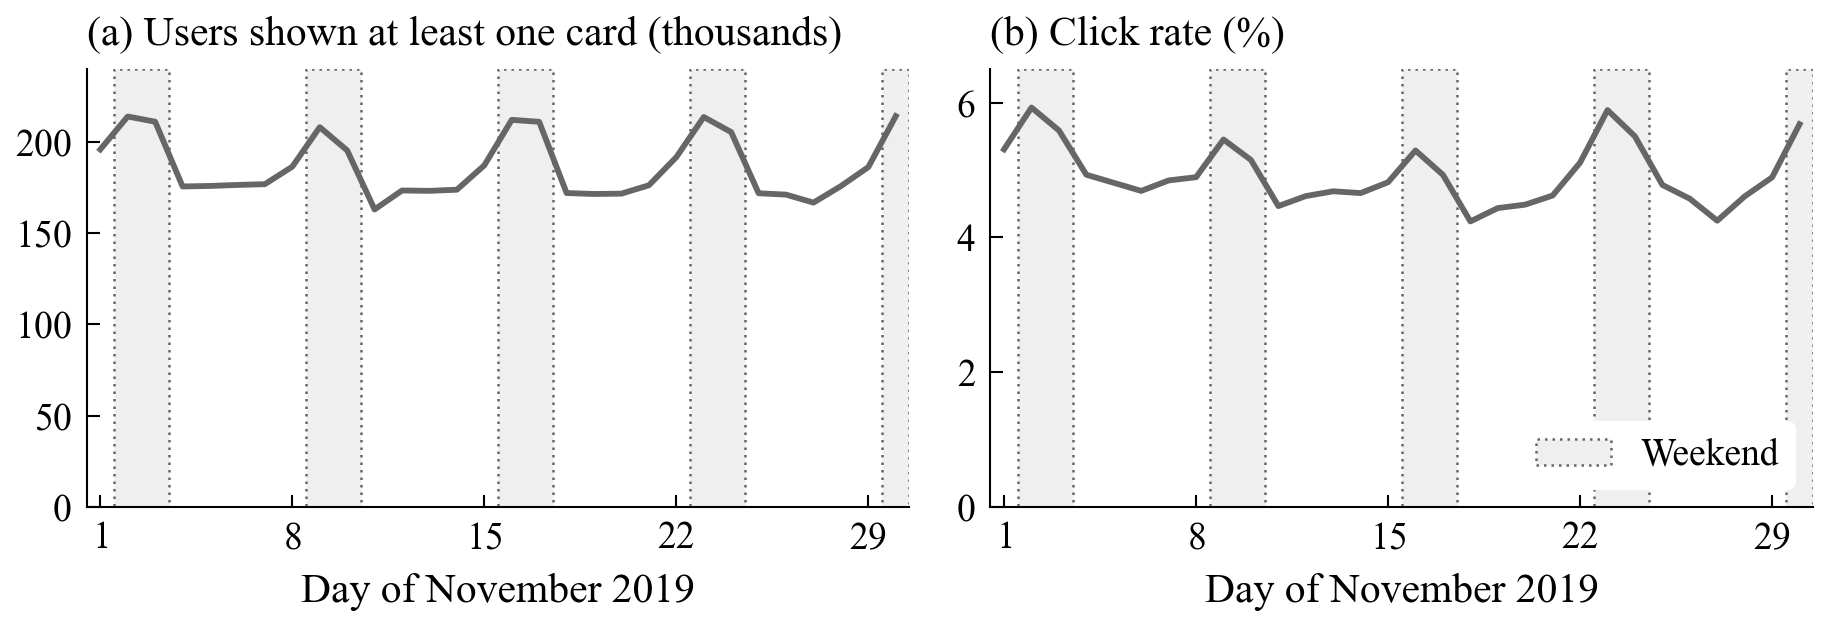

In [2]:
# Daily users and click rate, weekends shaded
d = C("02_daily_activity")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(W, 2.3))
a1.plot(d.dt, d.users / 1e3, color=BLUE, lw=1.4); a1.set_title("(a) Users shown at least one card (thousands)")
a2.plot(d.dt, 100 * d.click_rate, color=BLUE, lw=1.4); a2.set_title("(b) Click rate (%)")
for a in (a1, a2):
    shade_weekends(a); a.set_xlabel("Day of November 2019"); a.set_xticks([1, 8, 15, 22, 29]); a.set_xlim(0.5, 30.5)
a1.set_ylim(0, 240); a2.set_ylim(0, 6.5)
a2.legend(handles=[weekend_patch()], loc="lower right", frameon=True, facecolor="white", edgecolor="white", framealpha=1)
fig.tight_layout(); save(fig, "ch3_daily_activity")

### Figure 3.2: Users by first day seen

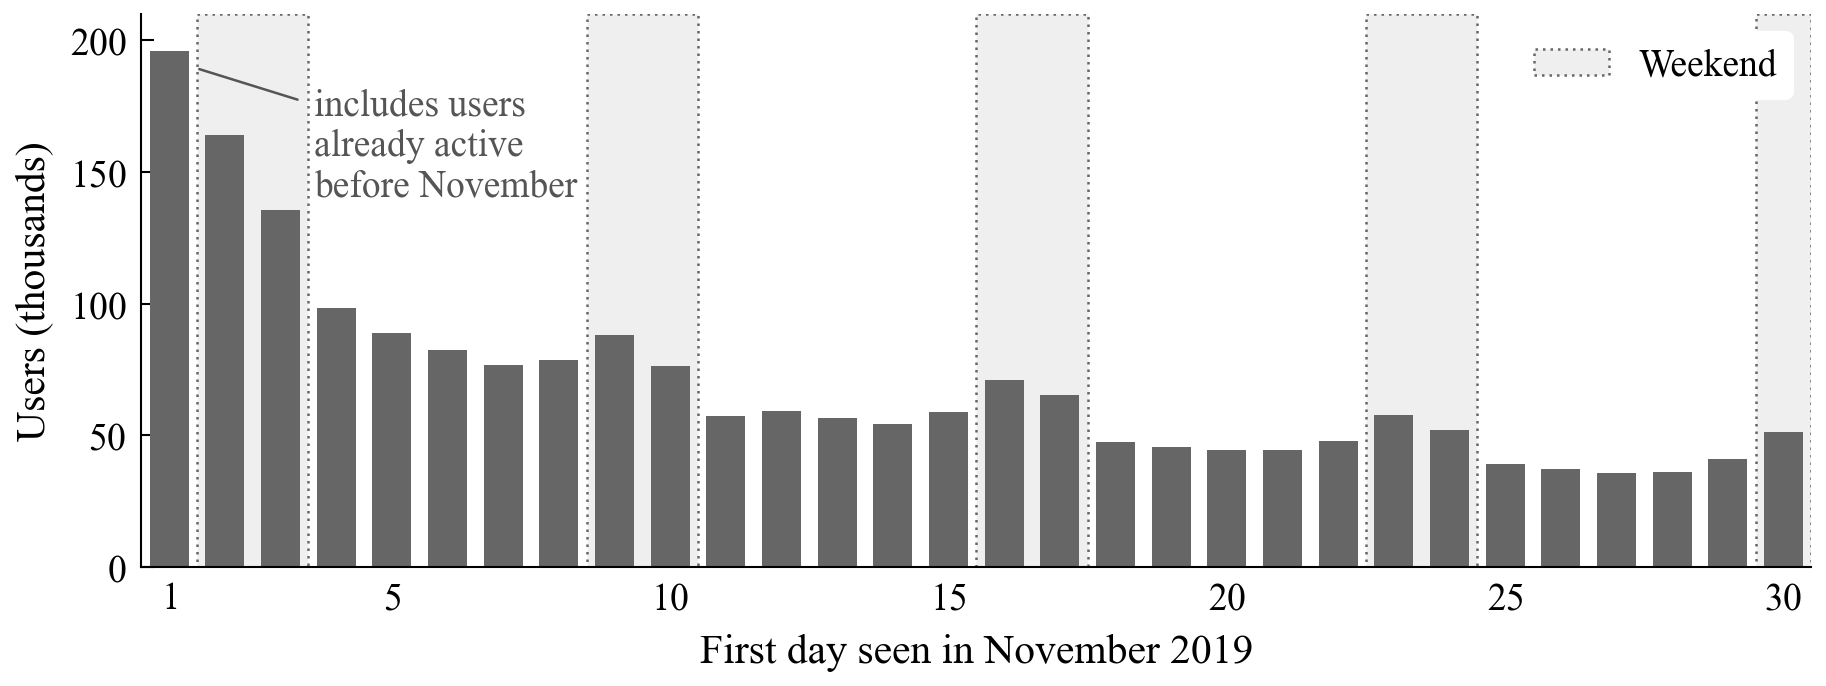

In [3]:
# Users by the first day they appear in the log, weekends shaded
d = C("02_first_seen_day")
fig, ax = plt.subplots(figsize=(W, 2.5))
shade_weekends(ax)
ax.bar(d.d0, d.users / 1e3, color=MID, width=0.7, zorder=2)
ax.annotate("includes users\nalready active\nbefore November", xy=(1.4, 190), xytext=(3.6, 182), fontsize=9, color=INK2,
            va="top", arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6))
ax.set_xlabel("First day seen in November 2019"); ax.set_ylabel("Users (thousands)")
ax.set_xticks([1, 5, 10, 15, 20, 25, 30]); ax.set_xlim(0.5, 30.5); ax.set_ylim(0, 210); categorical_x(ax)
ax.legend(handles=[weekend_patch()], loc="upper right", frameon=True, facecolor="white", edgecolor="white", framealpha=1)
fig.tight_layout(); save(fig, "ch3_first_seen_day")


### Figure 3.3: Return after a visit

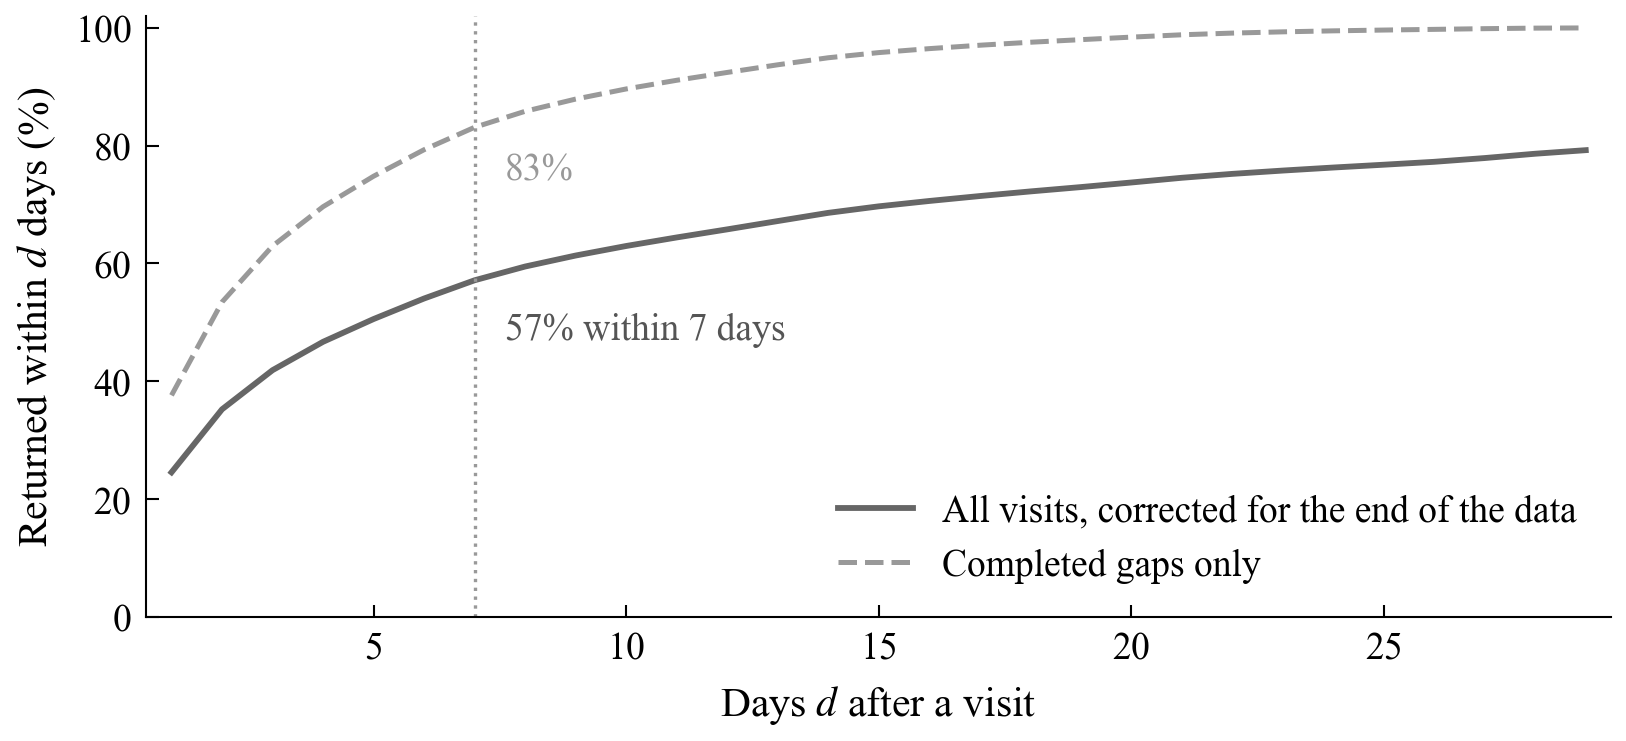

In [4]:
# Share of visits followed by another within d days: every visit followed until the user returns or the data ends
# (Kaplan-Meier), against the completed gaps alone, which overstate how quickly users return
d = C("03_time_to_next_visit")
fig, ax = plt.subplots(figsize=(W, 2.6))
ax.plot(d.d, 100 * d.share_returned_km, color=BLUE, lw=1.4, label="All visits, corrected for the end of the data")
ax.plot(d.d, 100 * d.share_returned_naive, color=REF, lw=1.2, ls="--", label="Completed gaps only")
ax.axvline(7, color=REF, lw=0.8, ls=":")
w7 = d.set_index("d").loc[7]
ax.annotate(f"{100 * w7.share_returned_km:.0f}% within 7 days", (7, 100 * w7.share_returned_km), xytext=(7.6, 100 * w7.share_returned_km - 10), fontsize=9, color=INK2)
ax.annotate(f"{100 * w7.share_returned_naive:.0f}%", (7, 100 * w7.share_returned_naive), xytext=(7.6, 100 * w7.share_returned_naive - 9), fontsize=9, color=REF)
ax.set_xlabel("Days $d$ after a visit"); ax.set_ylabel("Returned within $d$ days (%)")
ax.set_ylim(0, 102); ax.set_xlim(0.5, d.d.max() + 0.5); ax.legend(loc="lower right")
save(fig, "ch3_visit_gaps")

### Figure 3.4: Click rate and share of impressions by place in the feed

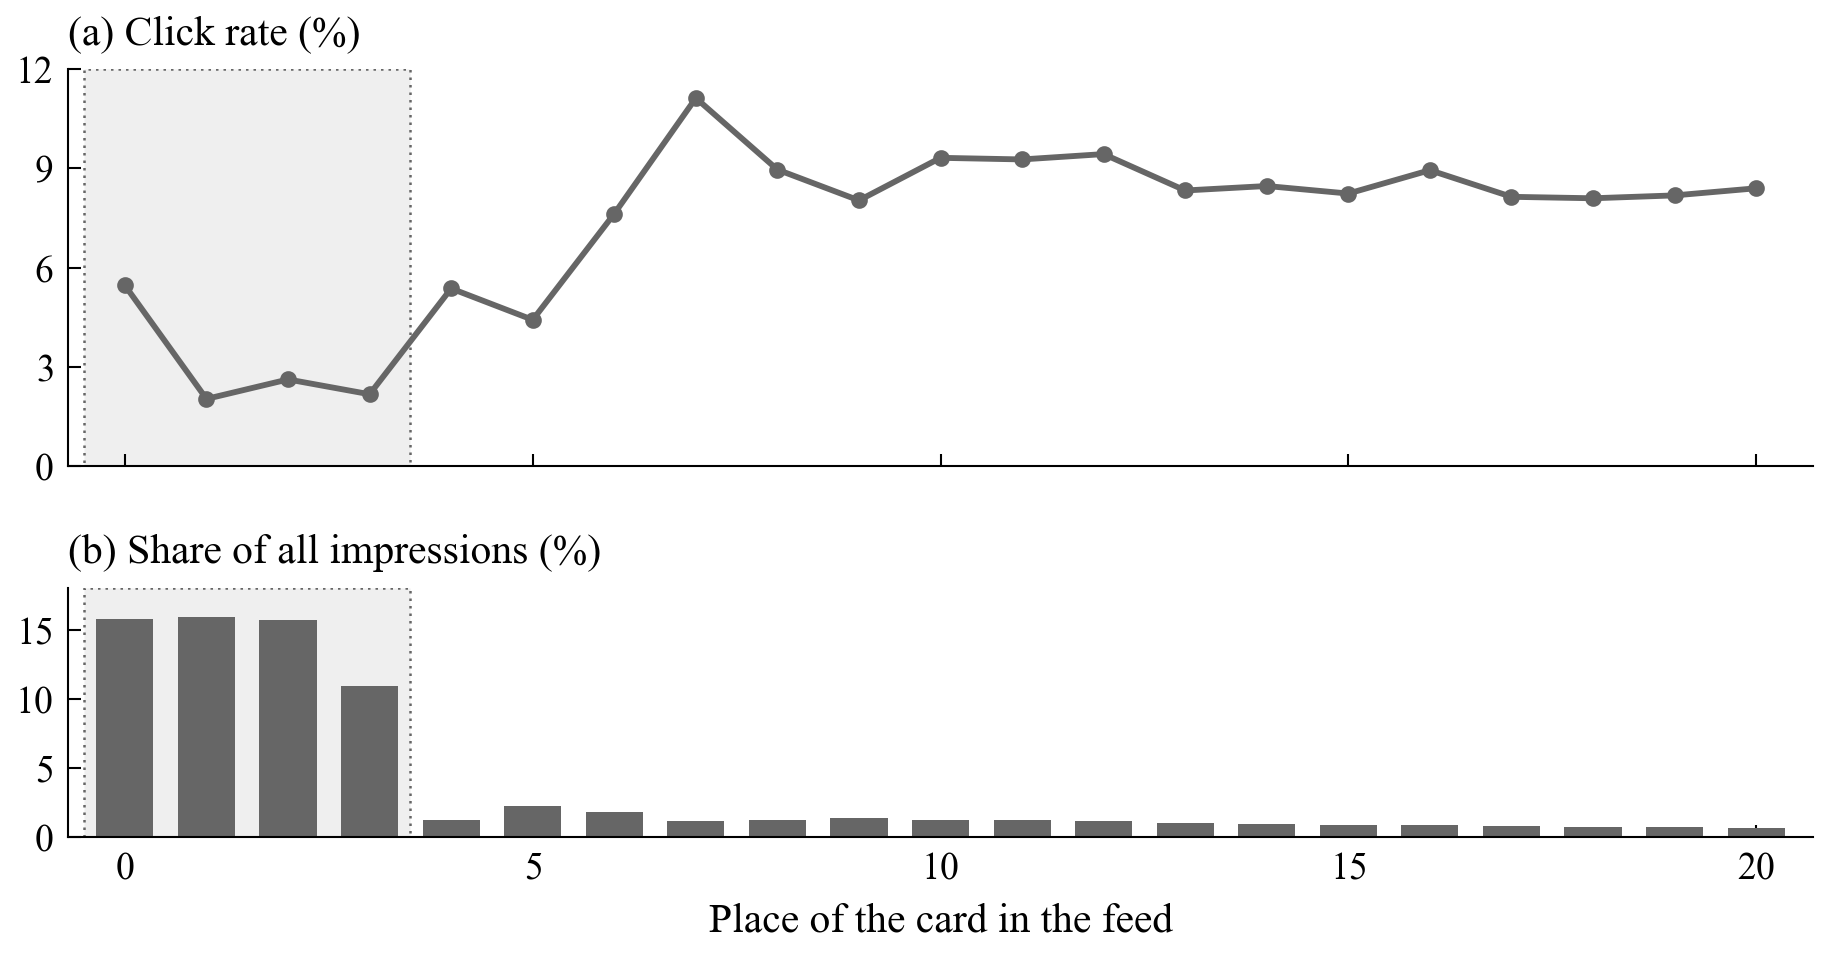

In [5]:
# Click rate (a) and share of all impressions (b) by place in the feed (counted from 0 on every page), places 0 to 20;
# the first page (places 0 to 3) shaded
d = C("02_click_rate_by_position").copy()
d["share"] = 100 * d.impressions / d.impressions.sum(); d["rate"] = 100 * d.click_rate
d = d[d.position <= 20]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(W, 3.4), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for a in (a1, a2): a.axvspan(-0.5, 3.5, facecolor=SHADE, edgecolor="#666666", linestyle=DOTTED, linewidth=0.6, zorder=0)
a1.plot(d.position, d.rate, color=BLUE, lw=1.4, marker="o", ms=3)
a1.set_title("(a) Click rate (%)"); a1.set_ylim(0, 12); a1.set_yticks([0, 3, 6, 9, 12])
a2.bar(d.position, d.share, color=MID, width=0.7, zorder=2)
a2.set_title("(b) Share of all impressions (%)"); a2.set_ylim(0, 18); a2.set_yticks([0, 5, 10, 15])
a2.set_xticks([0, 5, 10, 15, 20]); categorical_x(a2); a2.set_xlim(-0.7, 20.7); a2.set_xlabel("Place of the card in the feed")
fig.tight_layout(); save(fig, "ch3_click_rate_by_position")


### Figure 3.5: Click rate by place in the feed, by how far users scroll

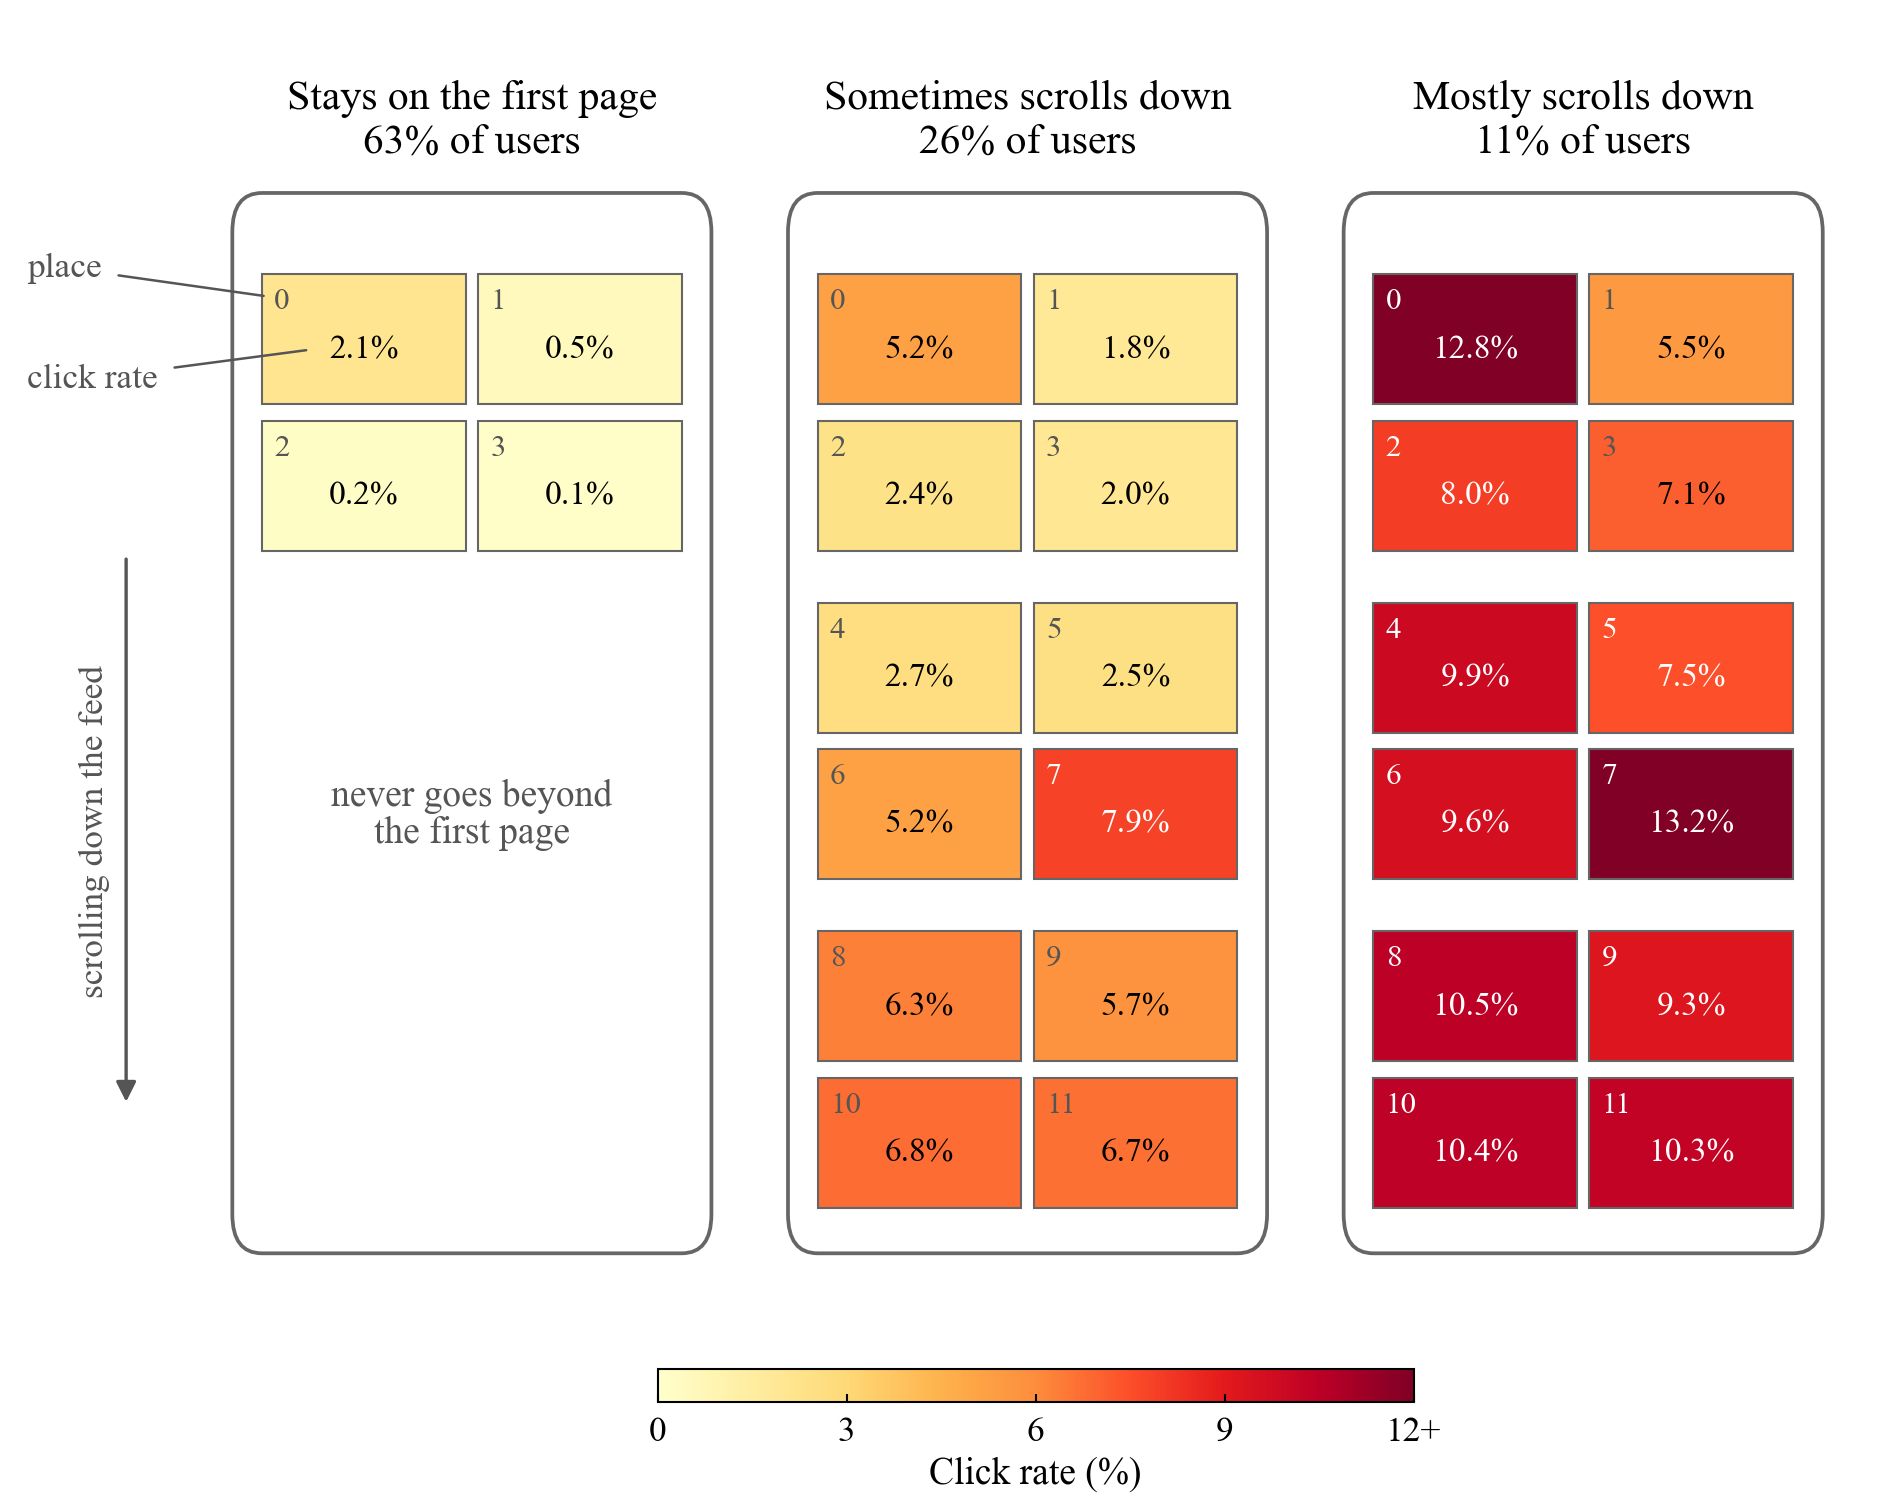

In [6]:
# The feed drawn as squares of four cards (two columns), one feed per scroll-depth group; each card shows its click rate
# on a yellow-to-red heat scale; places reached by under 0.5% of the group's impressions are dotted; the first group shows
# its first page only (by definition it never goes further)
import numpy as np, matplotlib as mpl
_cmap = mpl.colormaps["YlOrRd"]
_norm = mpl.colors.Normalize(0, 12)
COL = lambda r: _cmap(_norm(min(r, 12)))
def DARK(r):
    c = COL(r); return 0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2] < 0.5
def LEGEND(fig):
    cax = fig.add_axes([0.35, 0.045, 0.4, 0.022])
    sm = mpl.cm.ScalarMappable(norm=_norm, cmap=mpl.colors.ListedColormap([COL(x) for x in np.linspace(0, 12, 256)]))
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.set_ticks([0, 3, 6, 9, 12]); cb.set_ticklabels(["0", "3", "6", "9", "12+"]); cb.outline.set_linewidth(0.5)
    cax.tick_params(labelsize=8.5, length=2); cax.set_xlabel("Click rate (%)", fontsize=9, labelpad=2)
from matplotlib.patches import FancyBboxPatch, Rectangle
s = C("02_click_rate_by_position_scroll")
fig, ax = plt.subplots(figsize=(W, 5.0)); ax.axis("off")
PW, GAP, CG, CH, SG = 1.7, 0.55, 0.05, 0.40, 0.16; CW = (PW - CG) / 2
SH = C("02_scroll_groups").set_index("scroll_group").share
NAMES = {1: f"Stays on the first page\n{100*SH[1]:.0f}% of users", 2: f"Sometimes scrolls down\n{100*SH[2]:.0f}% of users", 3: f"Mostly scrolls down\n{100*SH[3]:.0f}% of users"}
def cell(x, y, p, g, tot):
    r = 100 * g.click_rate.get(p, 0); rare = g.impressions.get(p, 0) / tot < 0.005
    ax.add_patch(Rectangle((x, y), CW, CH, fc="white" if rare else COL(r), ec=REF if rare else "#666666",
                           lw=0.5, ls=DOTTED if rare else "-"))
    ax.text(x + 0.05, y + CH - 0.04, str(p), va="top", fontsize=7.5, color=REF if rare else ("white" if DARK(r) else INK2))
    ax.text(x + CW / 2, y + CH / 2 - 0.03, "rarely\nreached" if rare else f"{r:.1f}%", ha="center", va="center", fontsize=8,
            color=REF if rare else ("white" if DARK(r) else "black"), linespacing=0.9)
ys, y = {}, 0
for sq in range(3):                                   # three squares of four places: 0-3, 4-7, 8-11
    top = y - (SG if sq else CG)
    for row in range(2):
        for col in range(2):
            ys[4 * sq + 2 * row + col] = (top - (row + 1) * CH - row * CG, col)
    y = top - 2 * CH - CG
bottom = y
for j, k in enumerate((1, 2, 3)):
    g = s[s.scroll_group == k].set_index("position"); tot = g.impressions.sum(); x0 = j * (PW + GAP)
    ax.add_patch(FancyBboxPatch((x0 - 0.1, bottom - 0.12), PW + 0.2, -bottom + 0.3, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc="none", ec="#666666", lw=0.9))
    ax.text(x0 + PW / 2, 0.3, NAMES[k], ha="center", va="bottom", fontsize=10, linespacing=1.2)
    for p in range(4 if k == 1 else 12):
        yy, col = ys[p]; cell(x0 + col * (CW + CG), yy, p, g, tot)
    if k == 1:
        share = C("02_scroll_groups").set_index("scroll_group").share[1]
        ax.text(x0 + PW / 2, ys[4][0] - 0.25, "never goes beyond\nthe first page", ha="center",
                va="center", fontsize=9, color=INK2, linespacing=1.1)
y0 = ys[0][0]
ax.annotate("place", xy=(0.04, y0 + CH - 0.07), xytext=(-0.95, y0 + CH + 0.02), fontsize=8.5, color=INK2, va="center",
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6))
ax.annotate("click rate", xy=(CW / 2 - 0.2, y0 + CH / 2 - 0.03), xytext=(-0.95, y0 + CH / 2 - 0.12), fontsize=8.5, color=INK2,
            va="center", arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6))
ax.annotate("", xy=(-0.55, bottom + 0.3), xytext=(-0.55, y0 - 0.45), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=0.8))
ax.text(-0.68, (y0 - 0.45 + bottom + 0.3) / 2, "scrolling down the feed", rotation=90, ha="center", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(-1.0, 3 * PW + 2 * GAP + 0.3); ax.set_ylim(bottom - 0.25, 0.75)
LEGEND(fig)
fig.subplots_adjust(left=0.01, right=0.99, top=0.97, bottom=0.12); save(fig, "ch3_click_rate_grid")


### Figure 3.6: Cards shown and clicking in the two weeks after the first week

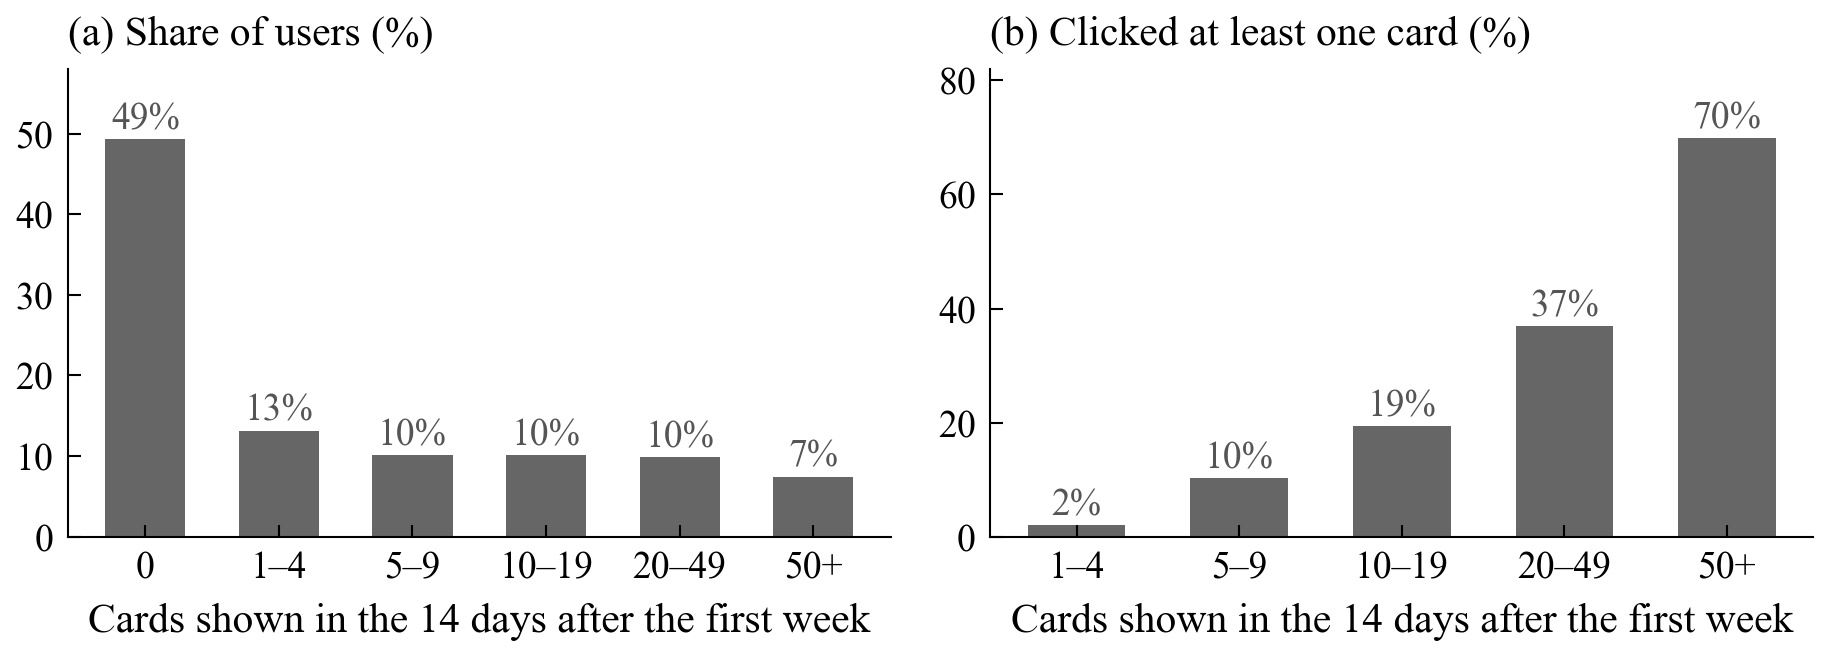

In [7]:
# Users by cards shown in the outcome window (a), and the share of them who click at least once (b)
d = C("02_outcome_exposure")
lab = [s.replace("-", "–") for s in d.out_impr.astype(str)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(W, 2.4))
a1.bar(lab, 100 * d.share, color=BLUE, width=0.6)
for i, v in enumerate(100 * d.share): a1.text(i, v + 1.2, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
a1.set_title("(a) Share of users (%)"); a1.set_ylim(0, 58)
k = d.out_impr.astype(str) != "0"                                     # nobody can click without being shown a card
a2.bar(np.array(lab)[k], 100 * d.share_any_click[k], color=BLUE, width=0.6)
for i, v in enumerate(100 * d.share_any_click[k]): a2.text(i, v + 1.6, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
a2.set_title("(b) Clicked at least one card (%)"); a2.set_ylim(0, 82)
for a in (a1, a2): a.set_xlabel("Cards shown in the 14 days after the first week"); categorical_x(a)
fig.tight_layout(); save(fig, "ch3_outcome_exposure")

## 3. Results: active users

### Figure 5.6: Differences between next week's groups

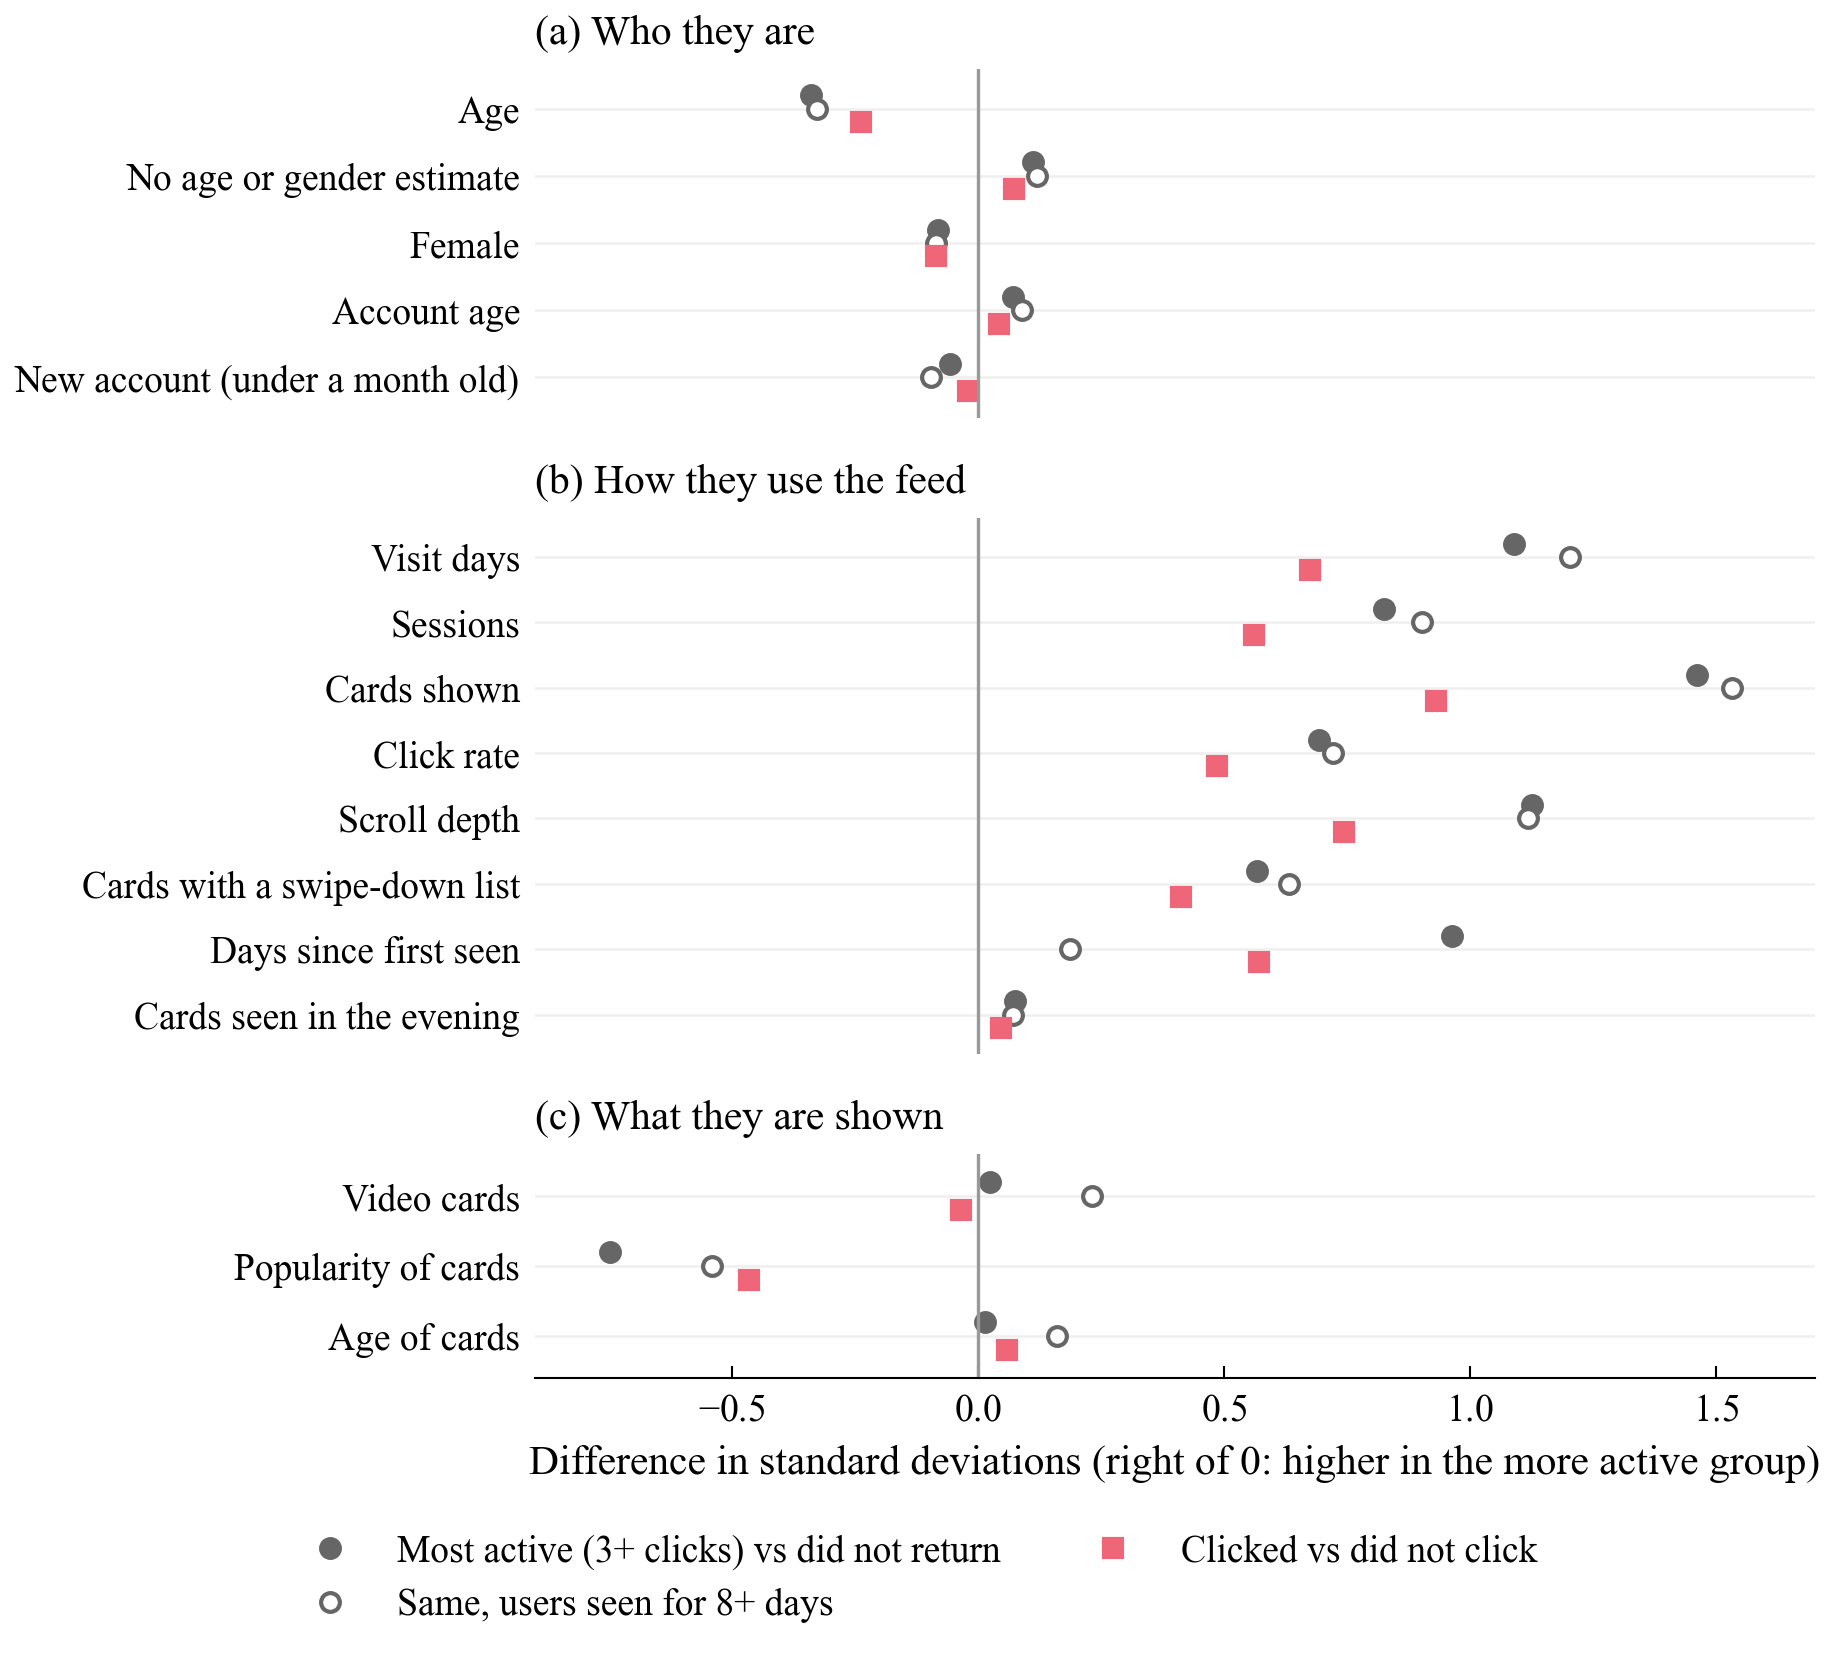

In [8]:
# Standardized differences between next week's groups (notebook 04), on one scale: (a) who they are, (b) how they use
# the feed, (c) what they are shown. Three comparisons per measure: the most active (3+ clicks) against users who did
# not return, the same among users first seen 8+ days before, and users who clicked against those who did not
d = C("25_rq1_differences").set_index(["sample", "attribute"]).smd
PANELS = [("(a) Who they are", [("age_n", "Age"), ("age_missing", "No age or gender estimate"), ("female", "Female"),
                                 ("log_tenure", "Account age"), ("new_account", "New account (under a month old)")]),
          ("(b) How they use the feed", [("w7_visit_days", "Visit days"), ("w7_sessions", "Sessions"),
                                          ("log_cards_7d", "Cards shown"), ("ctr_7d", "Click rate"),
                                          ("log_mean_position", "Scroll depth"),
                                          ("swipe_down_share", "Cards with a swipe-down list"),
                                          ("history_days", "Days since first seen"),
                                          ("evening", "Cards seen in the evening")]),
          ("(c) What they are shown", [("video_shown", "Video cards"), ("popularity_shown", "Popularity of cards"),
                                        ("card_age_shown", "Age of cards")])]
SERIES = [("3plus_vs_no_return_all", "Most active (3+ clicks) vs did not return", dict(marker="o", color=BLUE, mfc=BLUE)),
          ("3plus_vs_no_return_8days", "Same, users seen for 8+ days", dict(marker="o", color=BLUE, mfc="white")),
          ("click_vs_none_all", "Clicked vs did not click", dict(marker="s", color=RED, mfc=RED))]
fig, axs = plt.subplots(3, 1, figsize=(W, 5.6), sharex=True,
                        gridspec_kw={"height_ratios": [len(r) + 0.6 for _, r in PANELS]})
for ax, (title, rows) in zip(axs, PANELS):
    n = len(rows)
    for i, (attr, lab) in enumerate(rows):
        y = n - 1 - i
        ax.axhline(y, color=SHADE, lw=0.6, zorder=0)
        for j, (sample, name, st) in enumerate(SERIES):
            ax.plot(d[(sample, attr)], y + 0.2 - 0.2 * j, ls="none", ms=4.5, mew=1, label=name if i == 0 else None, **st)
    ax.axvline(0, color=REF, lw=0.8)
    ax.set_yticks(range(n), [lab for _, lab in rows][::-1]); ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False); ax.set_ylim(-0.6, n - 0.4); ax.set_title(title)
for ax in axs[:-1]:
    ax.tick_params(axis="x", length=0); ax.spines["bottom"].set_visible(False)
axs[-1].set_xticks([-0.5, 0, 0.5, 1, 1.5]); axs[-1].set_xlim(-0.9, 1.7)
axs[-1].set_xlabel("Difference in standard deviations (right of 0: higher in the more active group)")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.005))
save(fig, "ch5_group_differences")

### Figure 5.7: Usage segments

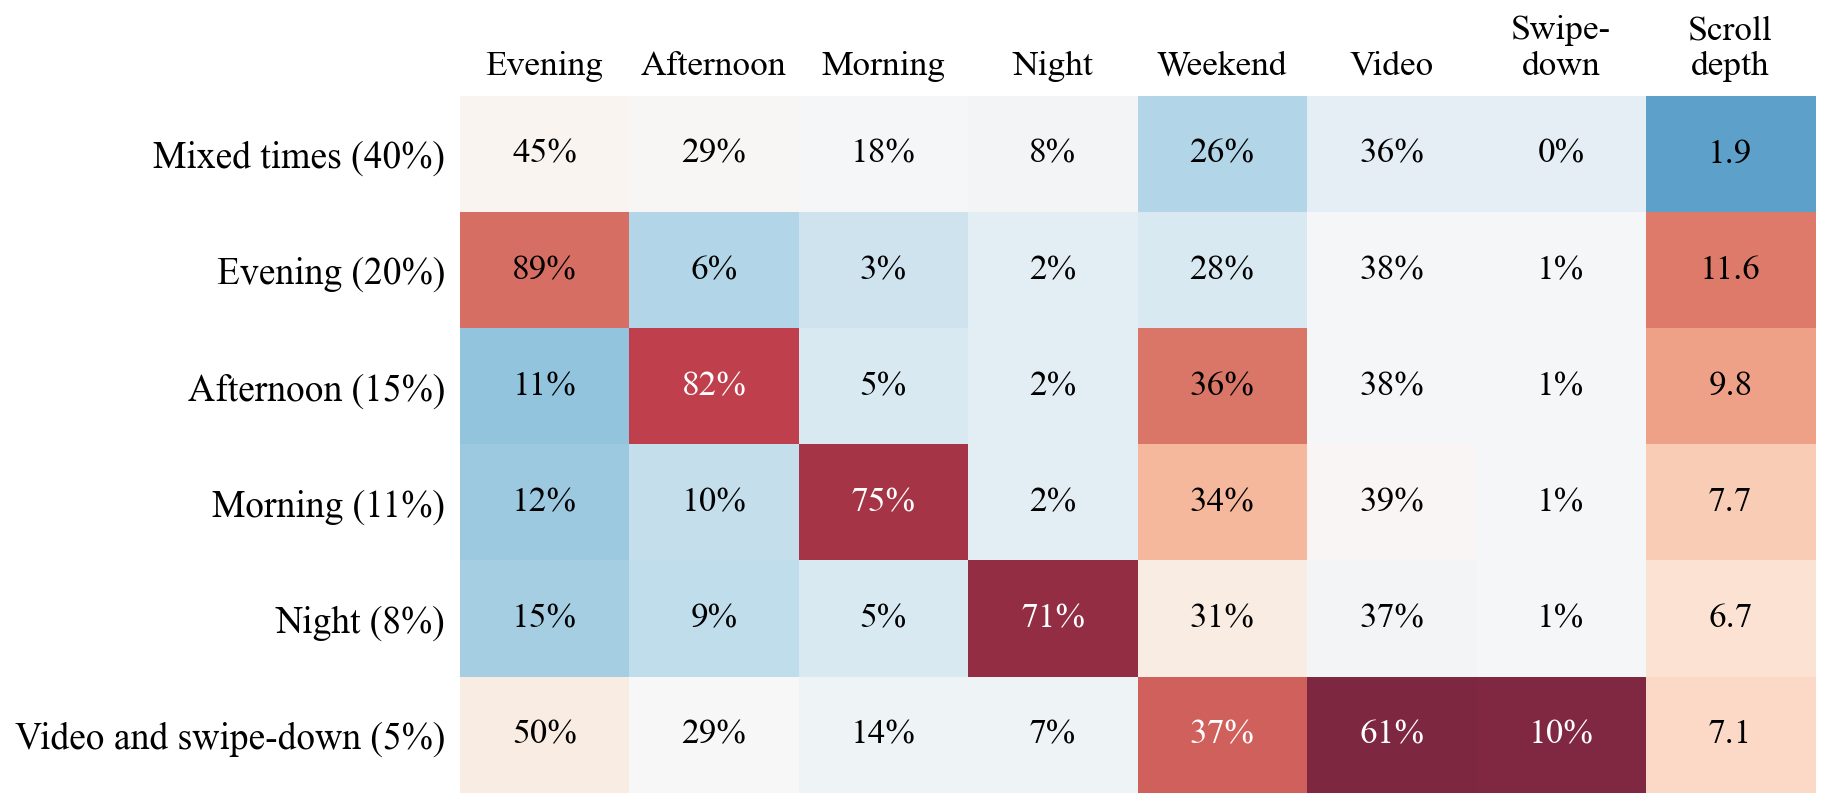

In [9]:
# Usage segments (notebook A2): each cluster's average mix of use. The number in a cell is the cluster's own average;
# the colour compares it with the average of all clustered users (red above, blue below, in standard deviations
# across the clusters). Clusters are named by what sets them apart and ordered by size.
import matplotlib as mpl
p = C("20_cluster_profiles")
COLS = [("evening", "Evening"), ("afternoon", "Afternoon"), ("morning", "Morning"), ("night", "Night"),
        ("weekend_share", "Weekend"), ("video_share", "Video"), ("swipe_down_share", "Swipe-\ndown"),
        ("log_mean_position", "Scroll\ndepth")]
def name(r):
    t = max(("evening", "afternoon", "morning", "night"), key=lambda c: r[c])
    if r[t] > 0.6: return t.capitalize()
    return "Video and swipe-down" if r.video_share == p.video_share.max() else "Mixed times"
p = p.assign(name=[name(r) for _, r in p.iterrows()], share=p.users / p.users.sum()).sort_values("users", ascending=False)
V = p[[c for c, _ in COLS]].to_numpy(float)
avg = (V * p.share.to_numpy()[:, None]).sum(0)
Z = (V - avg) / V.std(0)
fig, ax = plt.subplots(figsize=(W, 2.9))
ax.imshow(Z, cmap="RdBu_r", vmin=-2.6, vmax=2.6, aspect="auto", alpha=0.85)
for i_ in range(len(p)):
    for j_, (c, _) in enumerate(COLS):
        v = V[i_, j_]
        ax.text(j_, i_, f"{np.expm1(v):.1f}" if c == "log_mean_position" else f"{100 * v:.0f}%", ha="center", va="center", fontsize=8.5,
                color="white" if abs(Z[i_, j_]) > 1.7 else "black")
ax.set_xticks(range(len(COLS)), [l for _, l in COLS], fontsize=8.5); ax.xaxis.tick_top(); ax.tick_params(length=0)
ax.set_yticks(range(len(p)), [f"{n} ({100 * s:.0f}%)" for n, s in zip(p.name, p.share)])
for sp in ax.spines.values(): sp.set_visible(False)
fig.tight_layout(); save(fig, "ch5_segments")

## 4. Results: prediction

### Figure 5.4: Learning curve of new users

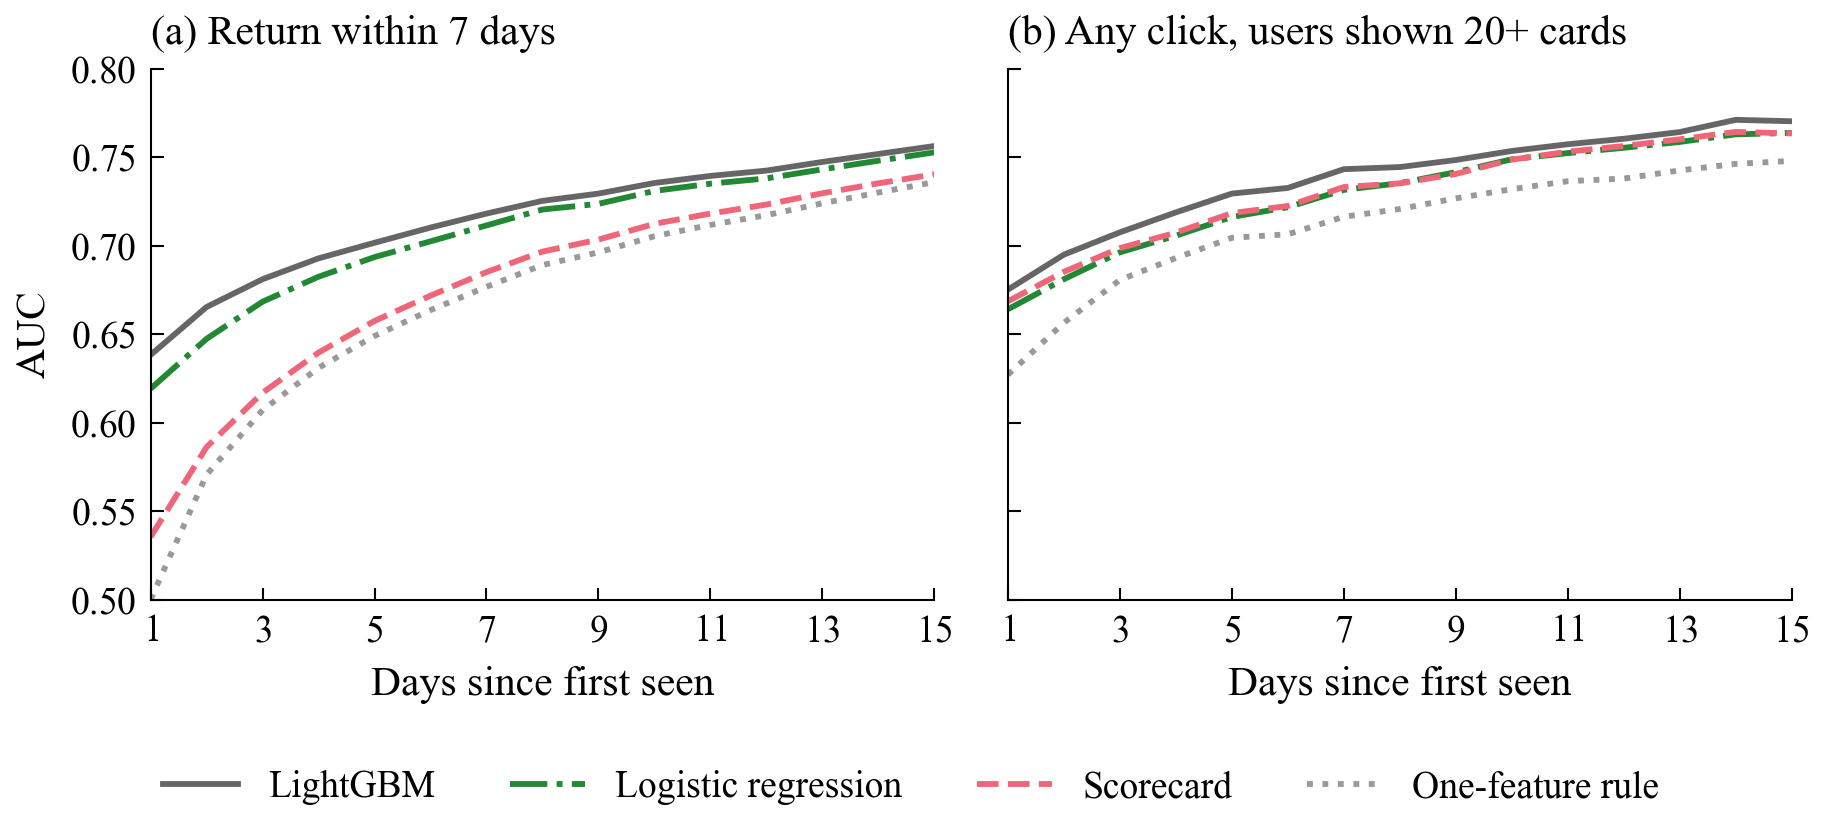

In [11]:
# The same test users (first seen on days 2 to 9) scored after 1 to 15 days since first seen, with every model refitted
# at each step (notebook 02, section 7): AUC of LightGBM, the logistic regression, the scorecard and the one-feature rule
hc = J("26_history_curve")["user_split"]
STY = {"lightgbm": ("LightGBM", BLUE, "-"), "logistic": ("Logistic regression", GREEN, "-."),
       "scorecard": ("Scorecard", RED, "--"), "baseline": ("One-feature rule", REF, ":")}
fig, axs = plt.subplots(1, 2, figsize=(W, 2.9), sharey=True)
for ax, (key, title) in zip(axs, (("R_return", "(a) Return within 7 days"),
                                  ("C_click_propensity", "(b) Any click, users shown 20+ cards"))):
    e = hc[key]; days = np.array([int(k) for k in e])
    for m, (name, col, ls) in STY.items():
        ax.plot(days, [e[k][f"{m}_auc"] for k in e], ls, color=col, lw=1.4, label=name)
    ax.set_title(title); ax.set_xlabel("Days since first seen")
    ax.set_xlim(1, 15); ax.set_xticks(range(1, 16, 2))
axs[0].set_ylabel("AUC"); axs[0].set_ylim(0.5, 0.8)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0))
save(fig, "ch5_learning_curve")

### Figure 5.1: Weights of the return scorecard

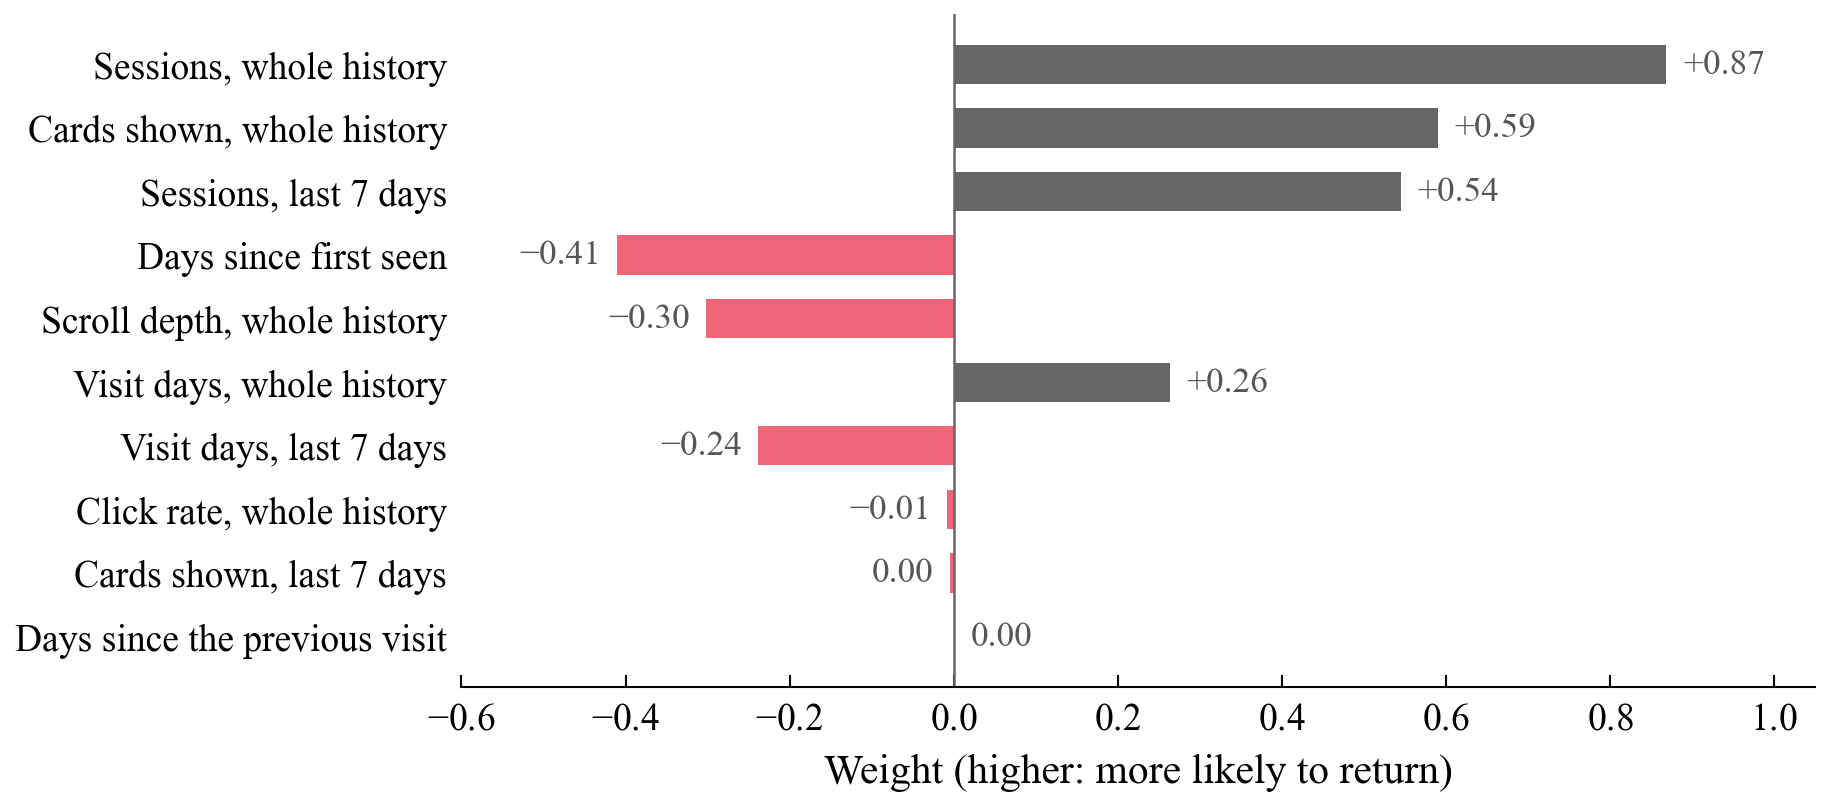

In [12]:
# Weights of the return scorecard: change in the log-odds of returning for a count one standard deviation higher
w = J("10_panel_models")["R_return"]["scorecard_coefficients_per_sd"]
NAMES = {"h_sessions": "Sessions, whole history", "h_impr": "Cards shown, whole history", "w7_sessions": "Sessions, last 7 days",
         "history_days": "Days since first seen", "h_mean_pos": "Scroll depth, whole history", "h_visit_days": "Visit days, whole history",
         "w7_visit_days": "Visit days, last 7 days", "h_ctr": "Click rate, whole history", "w7_impr": "Cards shown, last 7 days",
         "gap_since_prev_visit": "Days since the previous visit"}
rows = sorted(((NAMES[k], v) for k, v in w.items() if k in NAMES), key=lambda r: abs(r[1]))
fig, ax = plt.subplots(figsize=(W, 2.9))
y = np.arange(len(rows)); v = np.array([r[1] for r in rows])
ax.barh(y, v, color=[BLUE if x >= 0 else RED for x in v], height=0.62)
for yi, vi in zip(y, v):
    ax.text(vi + (0.02 if vi >= 0 else -0.02), yi, minus(f"{vi:+.2f}") if abs(vi) >= 0.005 else "0.00", va="center", ha="left" if vi >= 0 else "right", fontsize=8.5, color=INK2)
ax.axvline(0, color="#666666", lw=0.6); ax.set_yticks(y, [r[0] for r in rows]); categorical_y(ax); ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False); ax.set_xlim(-0.6, 1.05)
ax.set_xlabel("Weight (higher: more likely to return)")
fig.tight_layout(); save(fig, "ch5_scorecard_weights")

### Figure 5.2: Predicted and observed rates

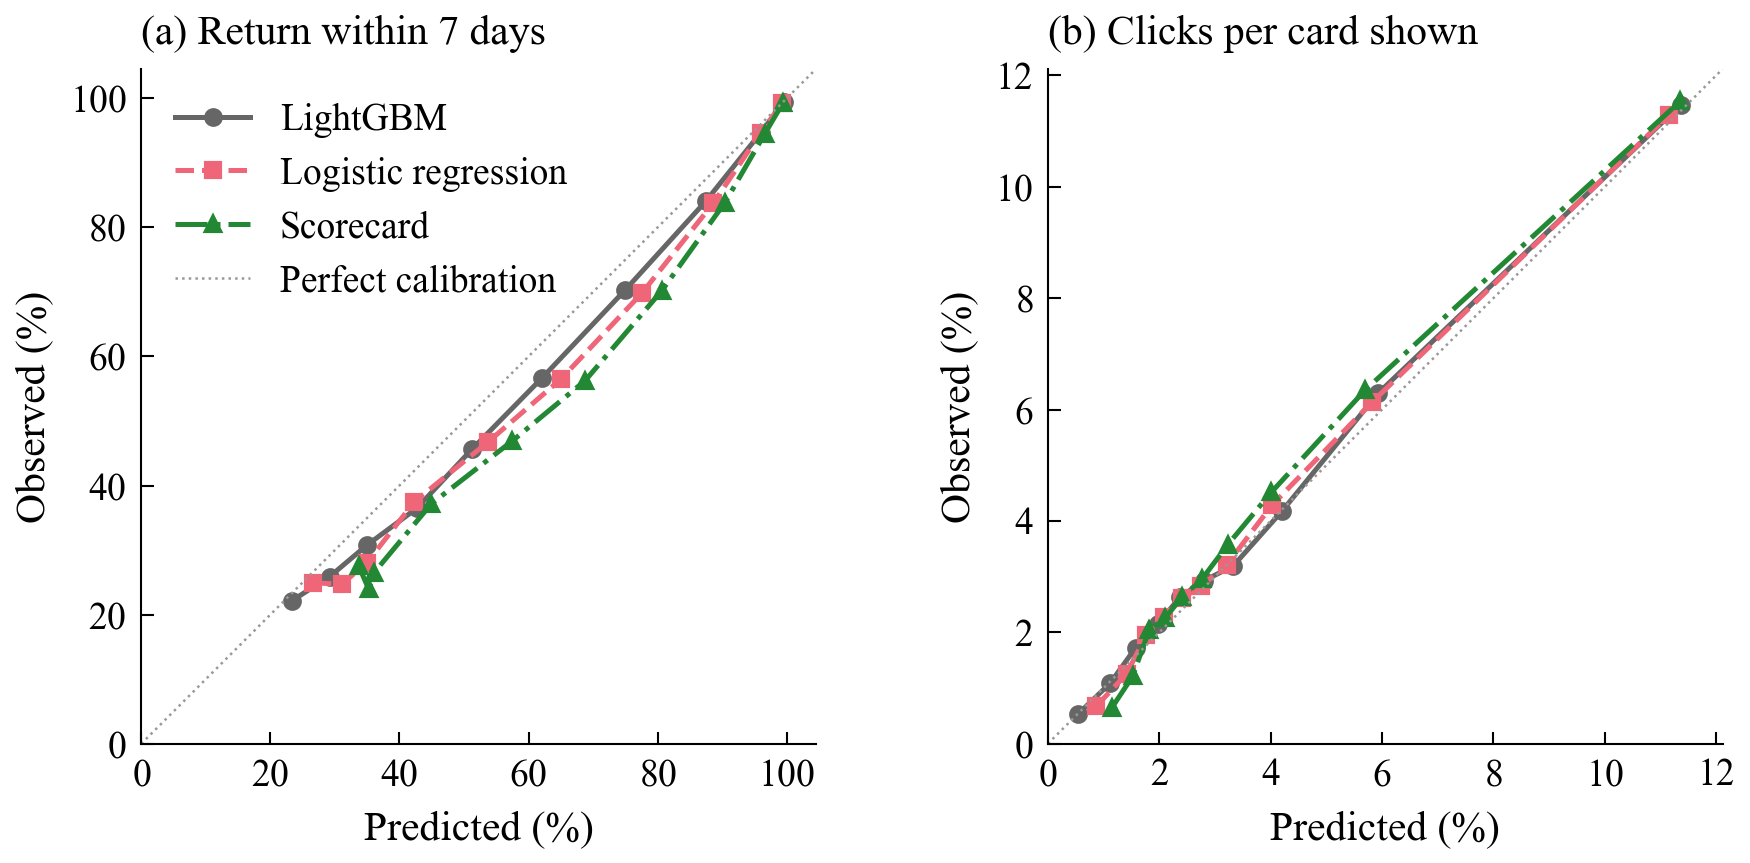

In [13]:
# Calibration: predicted against observed rates by tenth of predicted probability, test users
d = C("13_calibration_curve")
fig, axs = plt.subplots(1, 2, figsize=(W, 3.0))
for ax, (tgt, title) in zip(axs, (("R", "(a) Return within 7 days"), ("C", "(b) Clicks per card shown"))):
    for m, col, mk, ls, name in (("lightgbm", BLUE, "o", "-", "LightGBM"), ("logistic", RED, "s", "--", "Logistic regression"),
                                 ("scorecard", GREEN, "^", "-.", "Scorecard")):
        s = d[(d.target == tgt) & (d.model == m)]
        ax.plot(100 * s.predicted, 100 * s.observed, color=col, marker=mk, ls=ls, label=name)
    hi = 100 * d[d.target == tgt][["predicted", "observed"]].values.max() * 1.05
    ax.plot([0, hi], [0, hi], color=REF, lw=0.6, ls=":", label="Perfect calibration")
    ax.set_xlim(0, hi); ax.set_ylim(0, hi); ax.set_aspect("equal"); ax.set_title(title)
    ax.set_xticks(ax.get_yticks()[ax.get_yticks() <= hi]); ax.set_xlim(0, hi)
    ax.set_xlabel("Predicted (%)"); ax.set_ylabel("Observed (%)")
axs[0].legend(loc="upper left")
fig.tight_layout(); save(fig, "ch5_calibration")

### Figure 5.3: Accuracy by group of features

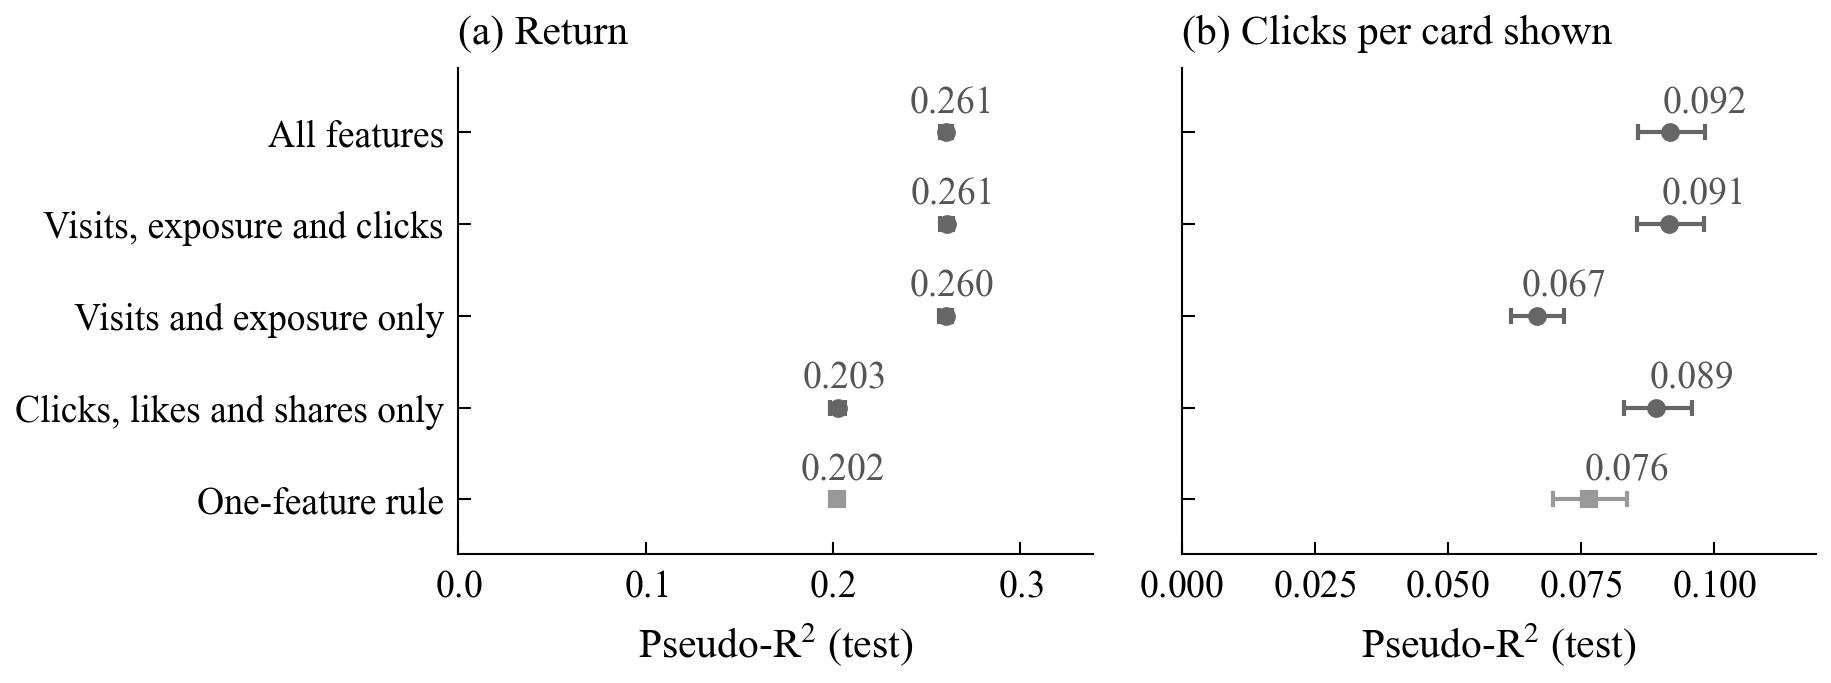

In [14]:
# Which early actions matter: pseudo-R² of LightGBM refitted on groups of features, with 95% intervals (cluster
# bootstrap over users). The baseline is one feature: visit days in the last 7 (return) or the user's past click rate,
# shrunk toward the average (clicks)
r = J("18_rq2_robustness")
groups = [("baseline", "One-feature rule"), ("clicks_social_only", "Clicks, likes and shares only"),
          ("visits_exposure", "Visits and exposure only"), ("visits_exposure+clicks", "Visits, exposure and clicks"),
          ("all_features_step10", "All features")]
fig, axs = plt.subplots(1, 2, figsize=(W, 2.5), sharey=True)
for ax, (key, title) in zip(axs, (("R_return", "(a) Return"), ("C_click_propensity", "(b) Clicks per card shown"))):
    e = r[key]["subsets"]["all"]
    for i, (g, name) in enumerate(groups):
        v, (lo, hi) = e[f"{g}_pseudo_r2"], e[f"{g}_pseudo_r2_ci95"]
        col, mk = (REF, "s") if g == "baseline" else (BLUE, "o")
        ax.errorbar(v, i, xerr=[[v - lo], [hi - v]], fmt=mk, color=col, lw=1)
        ax.text(hi, i + 0.22, f"{v:.3f}", ha="center", fontsize=9, color=INK2)
    ax.set_title(title); ax.set_xlabel("Pseudo-R$^2$ (test)")
    ax.set_xlim(0, max(e[f"{g}_pseudo_r2"] for g, _ in groups) * 1.3); categorical_y(ax)
axs[0].set_yticks(range(len(groups)), [n for _, n in groups]); axs[0].set_ylim(-0.6, len(groups) - 0.3)
fig.tight_layout(); save(fig, "ch5_feature_groups")

### Figure 5.5: The inactive label at each cutoff

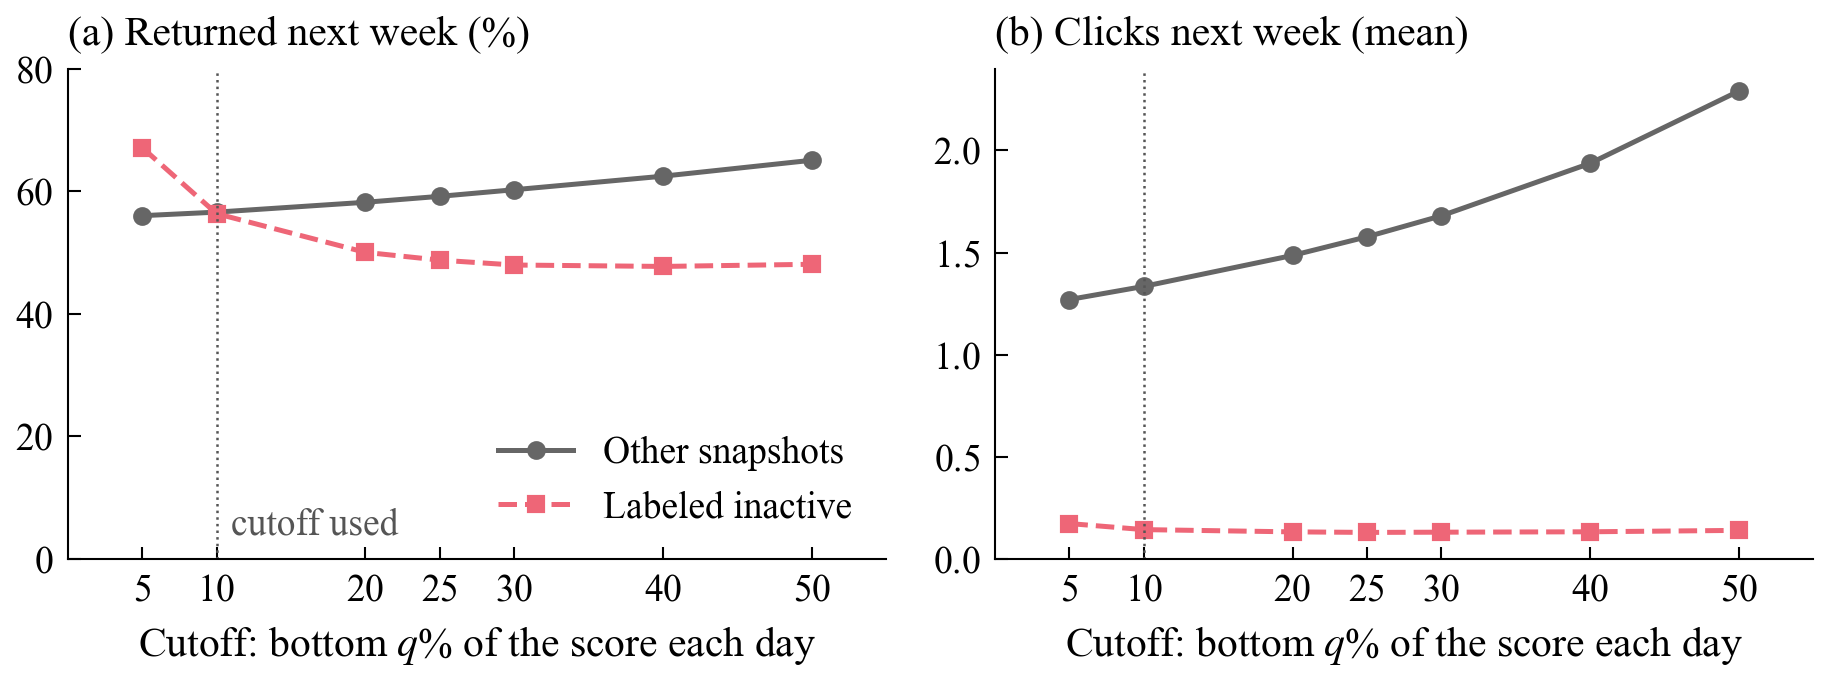

In [15]:
# The inactive label: what happens next week to users labeled inactive at each cutoff; 10% is the cutoff used
s = J("19_inactive_label")["by_threshold"]
q = [int(k.split("_")[1].rstrip("pct")) for k in s]
fig, axs = plt.subplots(1, 2, figsize=(W, 2.5))
for ax, (m, title, scale) in zip(axs, (("return_rate", "(a) Returned next week (%)", 100),
                                       ("mean_clicks", "(b) Clicks next week (mean)", 1))):
    ax.plot(q, [scale * s[k]["other"][m] for k in s], color=BLUE, marker="o", label="Other snapshots")
    ax.plot(q, [scale * s[k]["inactive"][m] for k in s], color=RED, marker="s", ls="--", label="Labeled inactive")
    ax.axvline(10, color=INK2, lw=0.6, ls=":")
    ax.set_xticks(q); categorical_x(ax); ax.set_xlim(0, 55); ax.set_ylim(0, None); ax.set_title(title)
    ax.set_xlabel("Cutoff: bottom $q$% of the score each day")
axs[0].set_ylim(0, 80); axs[0].legend(loc="lower right")
axs[0].annotate("cutoff used", (10, 4), xytext=(11, 4), fontsize=9, color=INK2)
fig.tight_layout(); save(fig, "ch5_inactive_label")

## 5. Results: recommender

### Figure 5.8: Click rate of each slot relative to the first

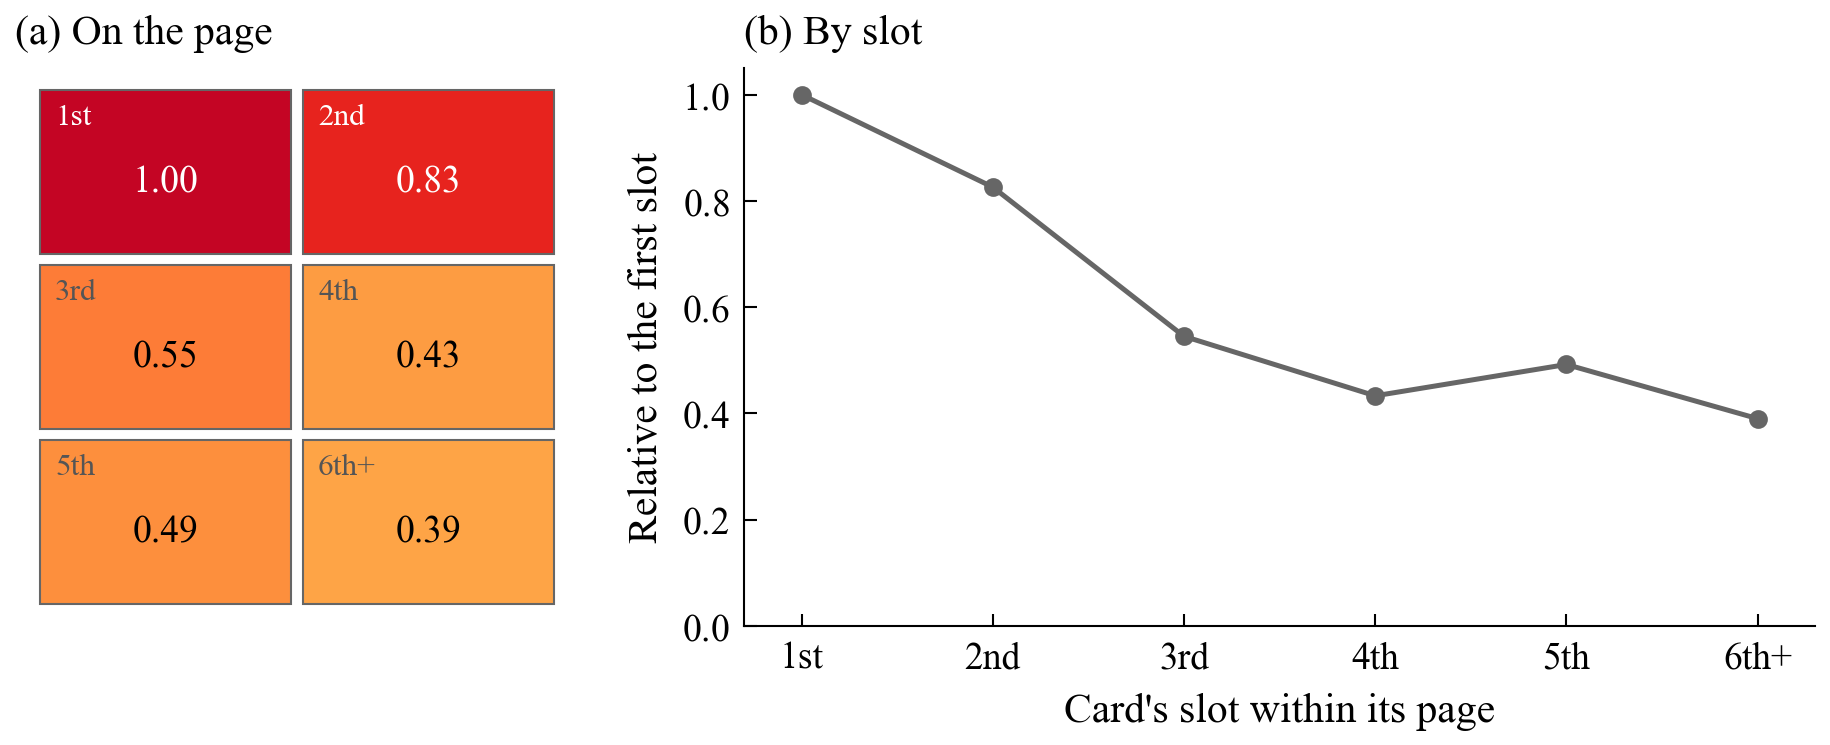

In [16]:
# Slot effects within a page (relative to the first card of the page): (a) drawn on a page of two columns, as the feed
# shows it, (b) by slot. One set of effects for all users (the model chosen on validation users pools the scroll groups)
import matplotlib as mpl
from matplotlib.patches import Rectangle
sf = np.reshape(J("21_rerank")["slot_factors"], (-1, 6))[0]
LAB = ["1st", "2nd", "3rd", "4th", "5th", "6th+"]
cmap = mpl.colormaps["YlOrRd"]; col = lambda v: cmap(0.15 + 0.7 * v)
fig, (a, b) = plt.subplots(1, 2, figsize=(W, 2.7), gridspec_kw={"width_ratios": [1, 1.9]})
a.axis("off"); a.set_title("(a) On the page")
for k, v in enumerate(sf):
    x, y = k % 2, 2 - k // 2
    c = col(v); dark = 0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2] < 0.5
    a.add_patch(Rectangle((x * 1.05, y * 0.8), 1, 0.75, fc=c, ec="#666666", lw=0.5))
    a.text(x * 1.05 + 0.06, y * 0.8 + 0.69, LAB[k], va="top", fontsize=7.5, color="white" if dark else INK2)
    a.text(x * 1.05 + 0.5, y * 0.8 + 0.33, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if dark else "black")
a.set_xlim(-0.1, 2.15); a.set_ylim(-0.1, 2.45)
slots = np.arange(1, 7)
b.plot(slots, sf, color=BLUE, marker="o")
b.set_xticks(slots, LAB); categorical_x(b); b.set_xlim(0.7, 6.3); b.set_ylim(0, 1.05); b.set_title("(b) By slot")
b.set_xlabel("Card's slot within its page"); b.set_ylabel("Relative to the first slot")
fig.tight_layout(); save(fig, "ch5_slot_effects")

### Figure 5.9: First-page features and the chance of returning

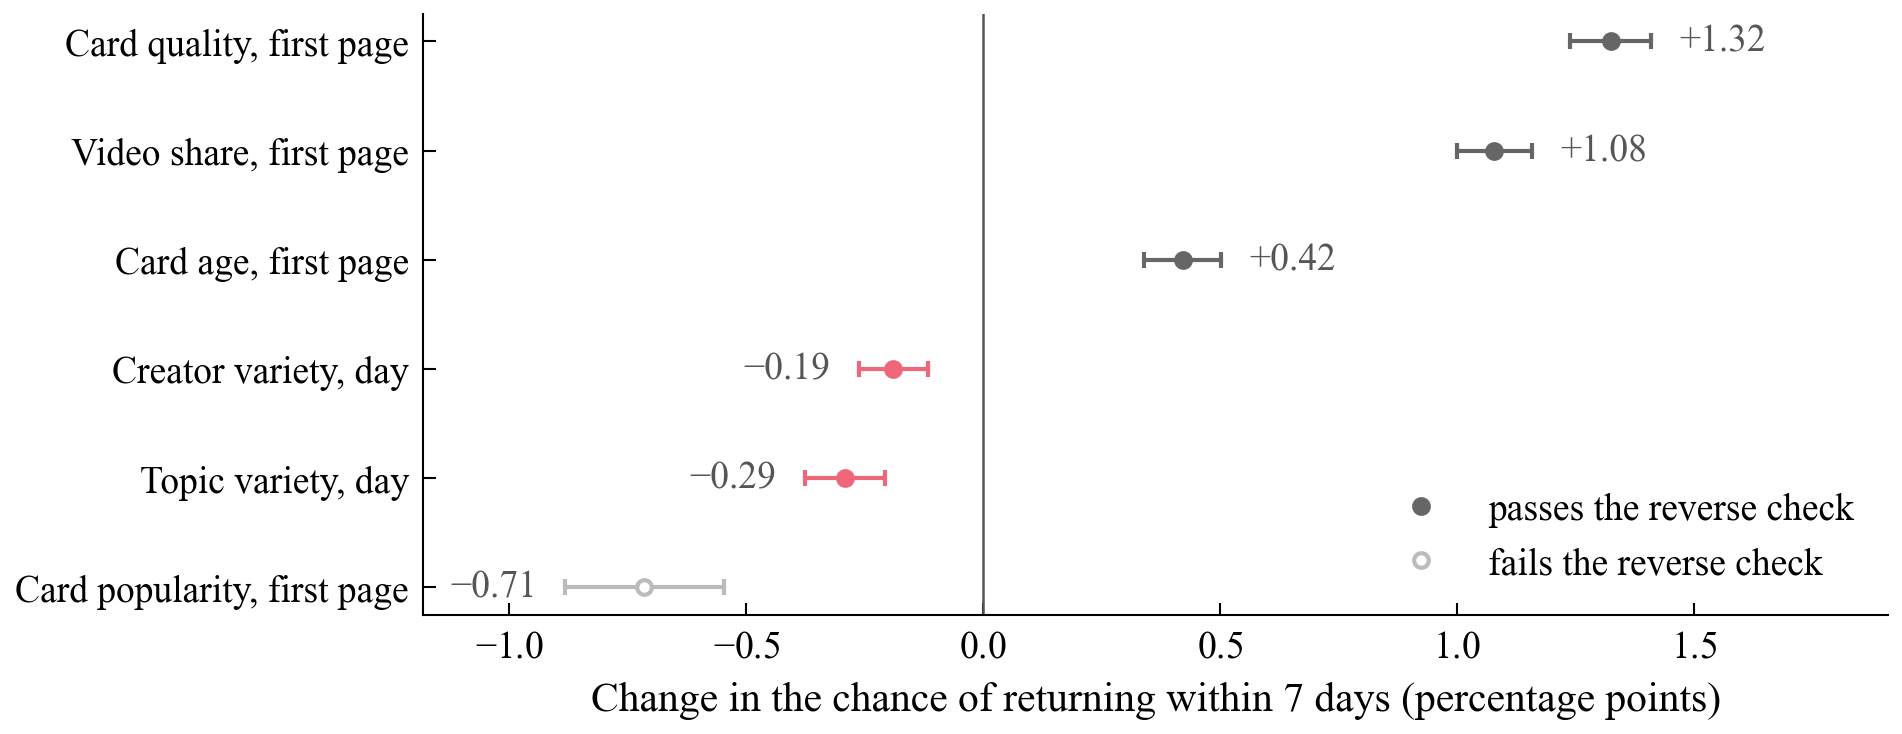

Reverse check, past-6-day visit days: {'popularity_z': {'coef': -0.20774, 'se': 0.00235, 'ci95': [-0.21234, -0.20314]}}


In [17]:
# Content levers: change in the chance of returning within 7 days per +1 within-user SD (95% CI); hollow = fails the
# reverse check (the feature also predicts activity in the days before it was shown)
cm = J("23_content_mix")["B_joint"]; b = cm["return_next7"]; rev = cm["reverse_check_past6_visit_days"]
names = [("quality_z", "Card quality, first page"), ("video_z", "Video share, first page"), ("age_z", "Card age, first page"),
         ("creator_variety_z", "Creator variety, day"), ("topic_variety_z", "Topic variety, day"), ("popularity_z", "Card popularity, first page")]
FAILS = {"popularity_z"}
fig, ax = plt.subplots(figsize=(W, 2.6))
for i, (k, name) in enumerate(names[::-1]):
    v, (lo, hi) = 100 * b[k]["coef"], [100 * x for x in b[k]["ci95"]]
    col = GREY if k in FAILS else (BLUE if v > 0 else RED)
    ax.errorbar(v, i, xerr=[[v - lo], [hi - v]], fmt="o", color=col, mfc="white" if k in FAILS else col, lw=1)
    ax.text(hi + 0.06 if v > 0 else lo - 0.06, i, minus(f"{v:+.2f}"), va="center", ha="left" if v > 0 else "right",
            fontsize=9, color=INK2)
ax.axvline(0, color=INK2, lw=0.6)
ax.set_yticks(range(len(names)), [n for _, n in names[::-1]]); categorical_y(ax)
ax.set_xlabel("Change in the chance of returning within 7 days (percentage points)")
ax.set_xlim(min(100 * b[k]["ci95"][0] for k, _ in names) - 0.3, max(100 * b[k]["ci95"][1] for k, _ in names) + 0.5)
ax.legend(handles=[Line2D([], [], color=BLUE, marker="o", ls="none", label="passes the reverse check"),
                   Line2D([], [], color=GREY, marker="o", mfc="white", ls="none", label="fails the reverse check")],
          loc="lower right")
save(fig, "ch5_content_levers")
print("Reverse check, past-6-day visit days:", {k: rev[k] for k in FAILS})

### Figure 5.10: Inactive snapshots lifted above the cutoff, by starting rank

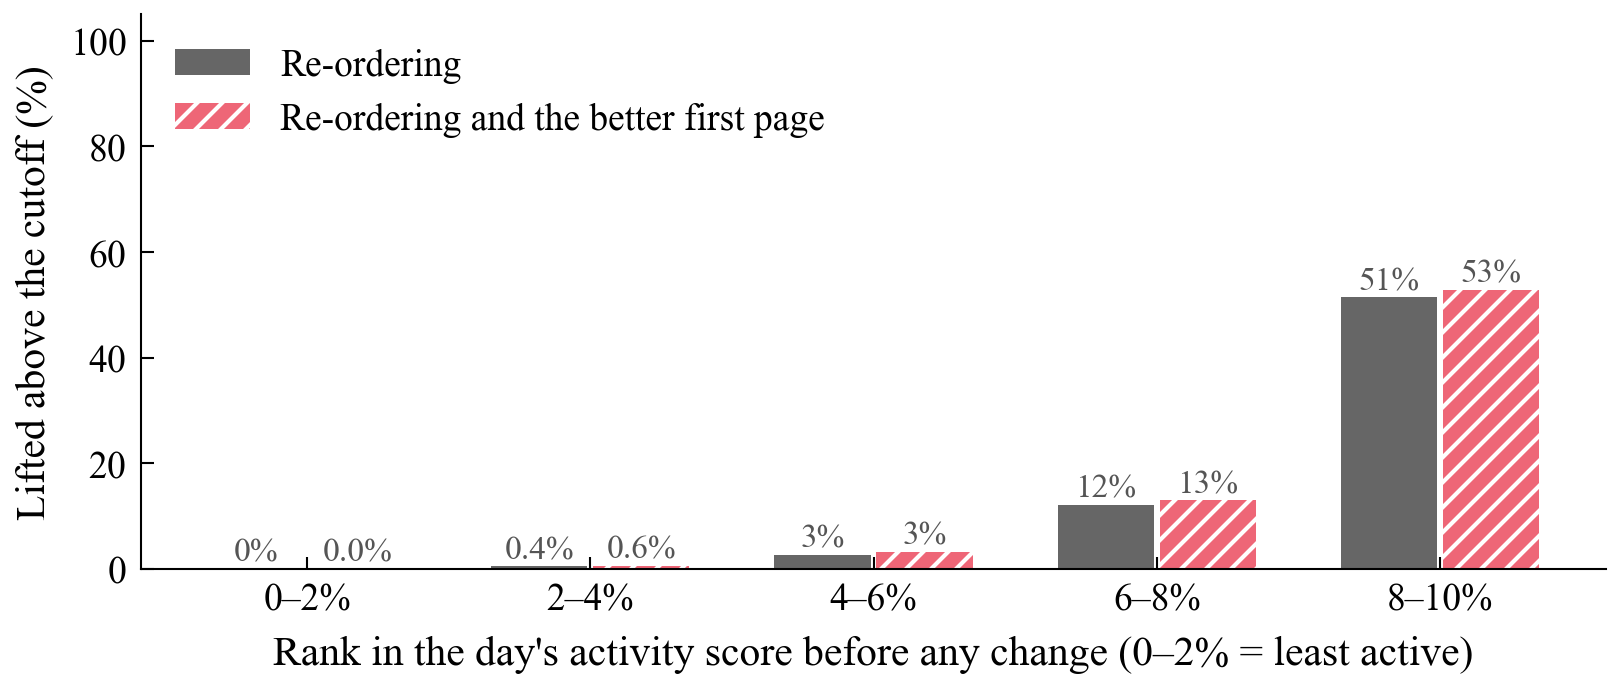

In [19]:
# Who moves: among snapshots inactive at baseline, the share lifted above the cutoff, by how far below it they start
w = P_["share_of_inactive_lifted_by_baseline_band"]
bands = list(next(iter(w.values()))); x = np.arange(len(bands))
fig, ax = plt.subplots(figsize=(W, 2.4))
for j, (k, col, hatch, name) in enumerate((("A_rerank_pages", BLUE, None, "Re-ordering"),
                                           ("A+best_feasible_first_page", RED, "////", "Re-ordering and the better first page"))):
    v = [100 * w[k][bd] for bd in bands]; xs = x + (j - 0.5) * 0.36
    ax.bar(xs, v, width=0.34, color=col, label=name, edgecolor="white", lw=0, hatch=hatch)
    for xi, vi in zip(xs, v): ax.text(xi, vi + 1.5, f"{vi:.0f}%" if vi >= 1 or vi == 0 else f"{vi:.1f}%", ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, [bd.replace("rank_", "").replace("%-", "–") for bd in bands]); categorical_x(ax)
ax.set_xlabel("Rank in the day's activity score before any change (0–2% = least active)"); ax.set_ylabel("Lifted above the cutoff (%)")
ax.legend(loc="upper left"); ax.set_ylim(0, 105)
save(fig, "ch5_who_moves")

In [20]:
sorted(p.name for p in FIG.glob(f"ch*{TAG}.pdf"))

['ch3_click_rate_by_position.pdf',
 'ch3_click_rate_grid.pdf',
 'ch3_daily_activity.pdf',
 'ch3_first_seen_day.pdf',
 'ch3_outcome_exposure.pdf',
 'ch3_visit_gaps.pdf',
 'ch5_auc_by_history.pdf',
 'ch5_calibration.pdf',
 'ch5_click_model_validation.pdf',
 'ch5_content_levers.pdf',
 'ch5_feature_groups.pdf',
 'ch5_group_differences.pdf',
 'ch5_group_profiles.pdf',
 'ch5_history_curve.pdf',
 'ch5_inactive_label.pdf',
 'ch5_learning_curve-1.pdf',
 'ch5_learning_curve.pdf',
 'ch5_policies.pdf',
 'ch5_scorecard_weights.pdf',
 'ch5_segments.pdf',
 'ch5_slot_effects.pdf',
 'ch5_tier_profiles.pdf',
 'ch5_who_moves.pdf']